# PENGEMBANGAN MODEL RANDOM FOREST BERBASIS EXPLAINABLE AI UNTUK DETEKSI ANCAMAN PHISHING PADA UNIFORM RESOURCE LOCATOR


## Import Library

In [1]:
import pandas as pd
import numpy as np
import re
import time
import warnings
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

import shap
import joblib

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

import sklearn
print("Versi library -> pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| shap", shap.__version__)

Versi library -> pandas 3.0.5 | numpy 2.4.6 | scikit-learn 1.9.0 | shap 0.51.0


## Pengumpulan & Penggabungan Dataset 

Dua sumber data digabungkan:
- **Kaggle** (`dataset_kaggle_1.csv`) — dataset *Malicious and Benign URLs* yang memuat URL berkategori `legitimate` dan `phishing`.
- **PhishTank** (`dataset_phishtank_1.csv`) — kumpulan URL *phishing* yang telah diverifikasi komunitas keamanan siber.

Label biner dibuat: **0 = legitimate**, **1 = phishing**. Apabila terdapat kategori lain selain `legitimate` dan `phishing` (mis. `defacement` atau `malware`), baris tersebut dibuang karena fokus penelitian ini adalah klasifikasi biner phishing vs legitimate.

In [2]:
kaggle = pd.read_csv("dataset_kaggle.csv")
phishtank = pd.read_csv("dataset_phishtank.csv")

kaggle["source"] = "Kaggle"
phishtank["source"] = "PhishTank"

dataset = pd.concat(
    [kaggle, phishtank],
    ignore_index=True
)

print("JUMLAH DATA AWAL (SEBELUM PREPROCESSING)")
print("Jumlah data Kaggle    :", len(kaggle))
print("Jumlah data PhishTank :", len(phishtank))
print("Total gabungan data   :", len(dataset))
print("===========================================\n")

dataset = dataset.drop_duplicates(subset="url")

print("JUMLAH SETELAH DROP DUPLICATE")
print(dataset["source"].value_counts())
print("Total gabungan data   :", len(dataset))
print("===========================================\n")

dataset["label"] = dataset["type"].map({
    "legitimate": 0,
    "phishing": 1
})

print("Kategori pada kolom 'type':")
print(dataset["type"].value_counts())
print("Total :", len(dataset))
print("\nJumlah baris dengan label NaN (kategori selain legitimate/phishing):",
      dataset["label"].isna().sum())

dataset = dataset.dropna(subset=["label"]).reset_index(drop=True)
dataset["label"] = dataset["label"].astype(int)

print("\nUkuran dataset akhir:", dataset.shape)
pd.concat([dataset.head(3), dataset.tail(3)])

JUMLAH DATA AWAL (SEBELUM PREPROCESSING)
Jumlah data Kaggle    : 579920
Jumlah data PhishTank : 65628
Total gabungan data   : 645548

JUMLAH SETELAH DROP DUPLICATE
source
Kaggle       579920
PhishTank     31135
Name: count, dtype: int64
Total gabungan data   : 611055

Kategori pada kolom 'type':
type
legitimate    339074
phishing      271981
Name: count, dtype: int64
Total : 611055

Jumlah baris dengan label NaN (kategori selain legitimate/phishing): 0

Ukuran dataset akhir: (611055, 4)


,url,type,source,label
0,http://%20%25**)(**@fbrasil.com/old/lqjj0ukuvg...,phishing,Kaggle,1
1,https://*f003.backblazeb2.com*/file/pesosi/hom...,phishing,Kaggle,1
2,http://0-docusign-secured-843439-1-srs09.repli...,phishing,Kaggle,1
611052,http://www.formbuddy.com/cgi-bin/formdisp.pl?u...,phishing,PhishTank,1
611053,http://www.habbocreditosparati.blogspot.com/,phishing,PhishTank,1
611054,http://creditiperhabbogratissicuro100.blogspot...,phishing,PhishTank,1


In [3]:
# Ambil 5 baris legitimate
legit_sample = kaggle[kaggle["type"] == "legitimate"].head(5)
print("=== 5 Contoh URL Legitimate (Kaggle) ===")
print(legit_sample)

print()

# Ambil 5 baris phishing
phishing_sample = kaggle[kaggle["type"] == "phishing"].head(5)
print("=== 5 Contoh URL Phishing (Kaggle) ===")
print(phishing_sample)

=== 5 Contoh URL Legitimate (Kaggle) ===
                                                    url        type  source
294                   http://0123456789nonexistent.com/  legitimate  Kaggle
1882  https://0.torrentoyunindir.com/bilgisayarinizd...  legitimate  Kaggle
1883  https://0.torrentoyunindir.com/bilgisayarinizd...  legitimate  Kaggle
1884  https://0.torrentoyunindir.com/bilgisayarinizd...  legitimate  Kaggle
1885  https://0.torrentoyunindir.com/bilgisayarinizd...  legitimate  Kaggle

=== 5 Contoh URL Phishing (Kaggle) ===
                                                 url      type  source
0  http://%20%25**)(**@fbrasil.com/old/lqjj0ukuvg...  phishing  Kaggle
1  https://*f003.backblazeb2.com*/file/pesosi/hom...  phishing  Kaggle
2  http://0-docusign-secured-843439-1-srs09.repli...  phishing  Kaggle
3                          http://0-olx.1850943.xyz/  phishing  Kaggle
4                http://0.0.0.0forum.cryptonight.net  phishing  Kaggle


## Eksplorasi Data (EDA)

            Jumlah Data  Persentase (%)
label                                  
Legitimate       339074           55.49
Phishing         271981           44.51

Total data: 611055


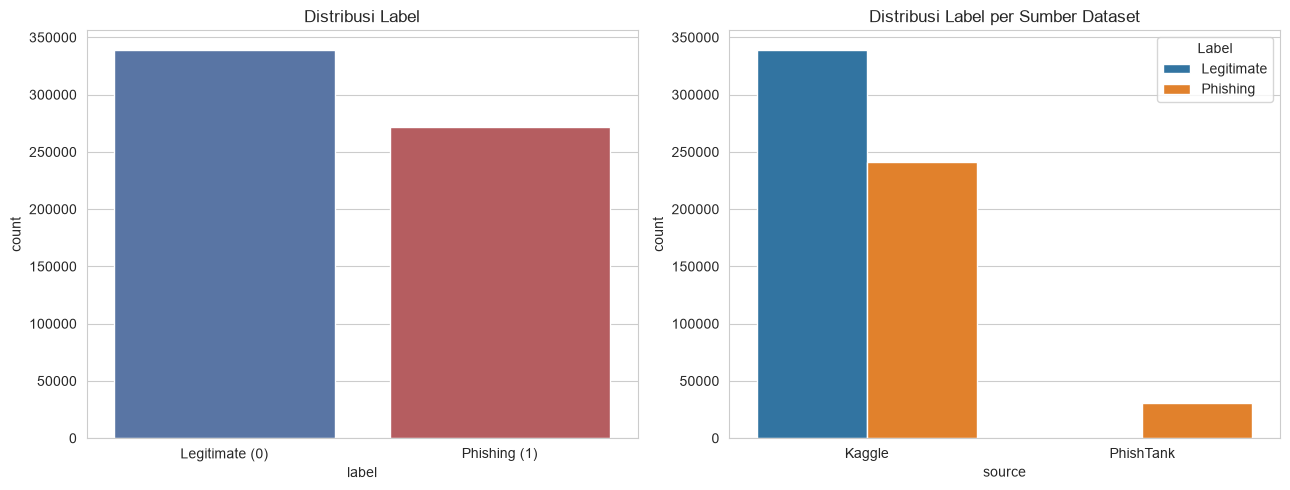

In [4]:
dist = dataset["label"].value_counts().rename({0: "Legitimate", 1: "Phishing"})
dist_pct = (dist / dist.sum() * 100).round(2)
print(pd.DataFrame({"Jumlah Data": dist, "Persentase (%)": dist_pct}))
print("\nTotal data:", dataset.shape[0])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=dataset, x="label", hue="label", ax=axes[0], palette=["#4C72B0", "#C44E52"], legend=False)
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["Legitimate (0)", "Phishing (1)"])
axes[0].set_title("Distribusi Label")
sns.countplot(data=dataset, x="source", hue="label", ax=axes[1])
axes[1].set_title("Distribusi Label per Sumber Dataset")
axes[1].legend(title="Label", labels=["Legitimate", "Phishing"])
plt.tight_layout()
plt.show()

## Ekstraksi Fitur Leksikal URL

Setiap URL ditransformasikan menjadi 32 fitur numerik yang mencakup karakteristik leksikal (panjang & frekuensi karakter), struktural (subdomain, pengulangan domain), dan indikator keamanan/penyamaran (protokol HTTPS, string acak). Fitur terdiri atas 14 fitur dasar ditambah 18 fitur leksikal tambahan (PathLength, QueryLength, NumSlash, NumDigits, DigitRatio, NumEquals, NumAt, NumQuestion, HostDigits, IsIP, NumKeywords, EntropyUrl, EntropyHost, NumSpecial, HasPort, NumUpper, HasWWW, TLDLength). Seluruh fitur dihitung hanya dari teks URL, tanpa WHOIS, reputasi domain, ataupun isi halaman.

In [5]:
import math
from collections import Counter

BASE_FEATURES = [
    "UrlLength", "NumDots", "SubdomainLevel", "NumDash", "NumUnderscore",
    "NumPercent", "NumQueryComponents", "NumAmpersand", "RandomString",
    "NoHttps", "DomainInPaths", "DomainInSubdomains", "HTTPSInHostname",
    "HostnameLength",
]
EXTRA_FEATURES = ['PathLength', 'QueryLength', 'NumSlash', 'NumDigits', 'DigitRatio', 'NumEquals', 'NumAt', 'NumQuestion', 'HostDigits', 'IsIP', 'NumKeywords', 'EntropyUrl', 'EntropyHost', 'NumSpecial', 'HasPort', 'NumUpper', 'HasWWW', 'TLDLength']
FEATURE_ORDER = BASE_FEATURES + EXTRA_FEATURES


SENSITIVE_KEYWORDS = ["login", "secure", "verify", "account", "update", "bank",
                      "signin", "confirm", "paypal", "password", "webscr", "ebay"]


def get_hostname(url):
    """Mengambil hostname (tanpa userinfo & port) dari sebuah URL."""
    url = str(url)
    parsed = urlparse(url if "://" in url else "http://" + url)
    hostname = parsed.netloc if parsed.netloc else url.split("/")[0]
    hostname = hostname.split("@")[-1]
    hostname = hostname.split(":")[0]
    return hostname.lower()


def get_domain_name(hostname):
    """Mengambil nama domain level-2 (tanpa subdomain & TLD)."""
    parts = hostname.split(".")
    if len(parts) >= 2:
        return parts[-2]
    return hostname


def is_random_string(s):
    """Heuristik RandomString: rasio vokal rendah / rangkaian konsonan panjang."""
    s = re.sub(r"[^a-zA-Z]", "", s)
    if len(s) < 4:
        return 0
    vowels = sum(1 for c in s.lower() if c in "aeiou")
    ratio = vowels / len(s)
    consonant_runs = re.findall(r"[^aeiou\d_]+", s.lower())
    max_run = max((len(r) for r in consonant_runs), default=0)
    return 1 if (ratio < 0.2 or max_run >= 5) else 0


def infer_no_https(url):
    """NoHttps: 1 = http://, 0 = https://. Skema tidak ditulis -> diasumsikan HTTPS."""
    u = url.lower()
    if u.startswith("https://"):
        return 0
    if u.startswith("http://"):
        return 1
    return 0


def shannon_entropy(s):
    """Entropi Shannon (bit per karakter) dari sebuah string."""
    if not s:
        return 0.0
    counts = Counter(s)
    n = len(s)
    return -sum((c / n) * math.log2(c / n) for c in counts.values())


def _has_port(parsed):
    try:
        return 1 if parsed.port is not None else 0
    except ValueError:
        return 0


def extract_features(url):
    """Mengekstrak seluruh fitur pada FEATURE_ORDER dari sebuah URL."""
    url = str(url).strip()
    parsed = urlparse(url if "://" in url else "http://" + url)
    hostname = get_hostname(url)
    path = parsed.path
    query = parsed.query
    domain_name = get_domain_name(hostname)

    host_parts = hostname.split(".")
    subdomain_part = ".".join(host_parts[:-2]) if len(host_parts) > 2 else ""

    # URL tanpa skema: dipakai agar fitur tambahan tidak bergantung pada ada/tidaknya "http(s)://"
    no_scheme = url.split("://", 1)[1] if "://" in url else url
    low = url.lower()

    feats = {}
    # --- 14 fitur dasar ---
    feats["UrlLength"] = len(url)
    feats["NumDots"] = url.count(".")
    feats["SubdomainLevel"] = max(hostname.count(".") - 1, 0)
    feats["NumDash"] = url.count("-")
    feats["NumUnderscore"] = url.count("_")
    feats["NumPercent"] = url.count("%")
    feats["NumQueryComponents"] = len([q for q in query.split("&") if q != ""]) if query else 0
    feats["NumAmpersand"] = url.count("&")
    feats["RandomString"] = is_random_string(domain_name)
    feats["NoHttps"] = infer_no_https(url)
    feats["DomainInPaths"] = 1 if domain_name and domain_name in path.lower() else 0
    feats["DomainInSubdomains"] = 1 if domain_name and domain_name in subdomain_part.lower() else 0
    feats["HTTPSInHostname"] = 1 if "https" in hostname else 0
    feats["HostnameLength"] = len(hostname)
    # --- fitur tambahan ---
    feats["PathLength"] = len(path)
    feats["QueryLength"] = len(query)
    feats["NumSlash"] = no_scheme.count("/")
    feats["NumDigits"] = sum(ch.isdigit() for ch in url)
    feats["DigitRatio"] = sum(ch.isdigit() for ch in no_scheme) / max(len(no_scheme), 1)
    feats["NumEquals"] = url.count("=")
    feats["NumAt"] = url.count("@")
    feats["NumQuestion"] = url.count("?")
    feats["HostDigits"] = sum(ch.isdigit() for ch in hostname)
    feats["IsIP"] = 1 if re.fullmatch(r"(\d{1,3}\.){3}\d{1,3}", hostname) else 0
    feats["NumKeywords"] = sum(k in low for k in SENSITIVE_KEYWORDS)
    feats["EntropyUrl"] = shannon_entropy(no_scheme)
    feats["EntropyHost"] = shannon_entropy(hostname)
    feats["NumSpecial"] = sum(not ch.isalnum() for ch in no_scheme)
    feats["HasPort"] = _has_port(parsed)
    feats["NumUpper"] = sum(ch.isupper() for ch in no_scheme)
    feats["HasWWW"] = 1 if hostname.startswith("www.") else 0
    feats["TLDLength"] = len(host_parts[-1]) if hostname else 0

    return {f: feats[f] for f in FEATURE_ORDER}

print(extract_features("http://verify-secure-login.tk/account/update?id=123&x=1"))
print(extract_features("https://https-paypal-secure.verify-account123.com/login"))

{'UrlLength': 55, 'NumDots': 1, 'SubdomainLevel': 0, 'NumDash': 2, 'NumUnderscore': 0, 'NumPercent': 0, 'NumQueryComponents': 2, 'NumAmpersand': 1, 'RandomString': 0, 'NoHttps': 1, 'DomainInPaths': 0, 'DomainInSubdomains': 0, 'HTTPSInHostname': 0, 'HostnameLength': 22, 'PathLength': 15, 'QueryLength': 10, 'NumSlash': 2, 'NumDigits': 4, 'DigitRatio': 0.08333333333333333, 'NumEquals': 2, 'NumAt': 0, 'NumQuestion': 1, 'HostDigits': 0, 'IsIP': 0, 'NumKeywords': 5, 'EntropyUrl': 4.647055208874202, 'EntropyHost': 3.9705730958116834, 'NumSpecial': 9, 'HasPort': 0, 'NumUpper': 0, 'HasWWW': 0, 'TLDLength': 2}
{'UrlLength': 55, 'NumDots': 2, 'SubdomainLevel': 1, 'NumDash': 3, 'NumUnderscore': 0, 'NumPercent': 0, 'NumQueryComponents': 0, 'NumAmpersand': 0, 'RandomString': 0, 'NoHttps': 0, 'DomainInPaths': 0, 'DomainInSubdomains': 0, 'HTTPSInHostname': 1, 'HostnameLength': 41, 'PathLength': 6, 'QueryLength': 0, 'NumSlash': 1, 'NumDigits': 3, 'DigitRatio': 0.06382978723404255, 'NumEquals': 0, 'NumA

## Seleksi Fitur dengan Permutation Importance

Fungsi `extract_features` di atas menghasilkan **32 fitur**. Sebelum fitur diekstraksi untuk seluruh dataset, dilakukan seleksi fitur dengan *permutation importance* supaya tahap berikutnya (ekstraksi penuh, augmentasi, GridSearchCV, evaluasi, dan SHAP) hanya memproses fitur yang berpengaruh.

Alur seleksi:

1. Diambil **sampel** dari data latih (bagian 70% dari pembagian utama), lalu 32 fitur diekstraksi hanya untuk sampel tersebut dan dibagi menjadi data latih-seleksi (80%) dan data validasi-seleksi (20%).
2. Model Random Forest sementara dilatih dengan 32 fitur. **Permutation importance** dihitung pada data validasi-seleksi: nilai satu fitur diacak, lalu diukur penurunan F1-score dan ROC-AUC. Fitur yang penurunannya di bawah `PI_THRESHOLD` pada kedua metrik menjadi kandidat hapus.
3. Fitur yang berkorelasi saling menutupi, jadi jumlah fitur yang dihapus dicari dengan *binary search*; tiap kandidat dilatih ulang dan harus menjaga metrik validasi (>= 0,90 dan penurunan F1 <= `MAX_DROP_F1`).
4. Fitur tersisa (`FEATURE_SELECTED`) dipakai pada seluruh tahap berikutnya.

Sampel hanya diambil dari data latih utama, sehingga **data validasi dan data uji utama tidak tersentuh** pada tahap ini (pembagian memakai `random_state` dan stratifikasi yang sama dengan pembagian utama).

Ekstraksi 32 fitur untuk 150,000 URL sampel: 20.5 detik
Data latih-seleksi: (120000, 32) | Data validasi-seleksi: (30000, 32)
Model sementara 32 fitur dilatih dalam 9.3 detik
Metrik validasi-seleksi (32 fitur): {'Accuracy': 0.9489, 'Precision': 0.9496, 'Recall': 0.9347, 'F1': 0.9421, 'ROC-AUC': 0.9884}
Permutation importance selesai dalam 151.1 detik

                    F1_turun_mean  F1_turun_std  AUC_turun_mean  AUC_turun_std
PathLength                0.10723       0.00145         0.04177        0.00052
HasWWW                    0.08226       0.00121         0.04094        0.00074
HostnameLength            0.03567       0.00103         0.01483        0.00017
NoHttps                   0.02455       0.00037         0.00778        0.00010
NumUpper                  0.01359       0.00068         0.00464        0.00013
NumDots                   0.01245       0.00045         0.00582        0.00014
DigitRatio                0.00979       0.00051         0.00423        0.00016
EntropyUrl    

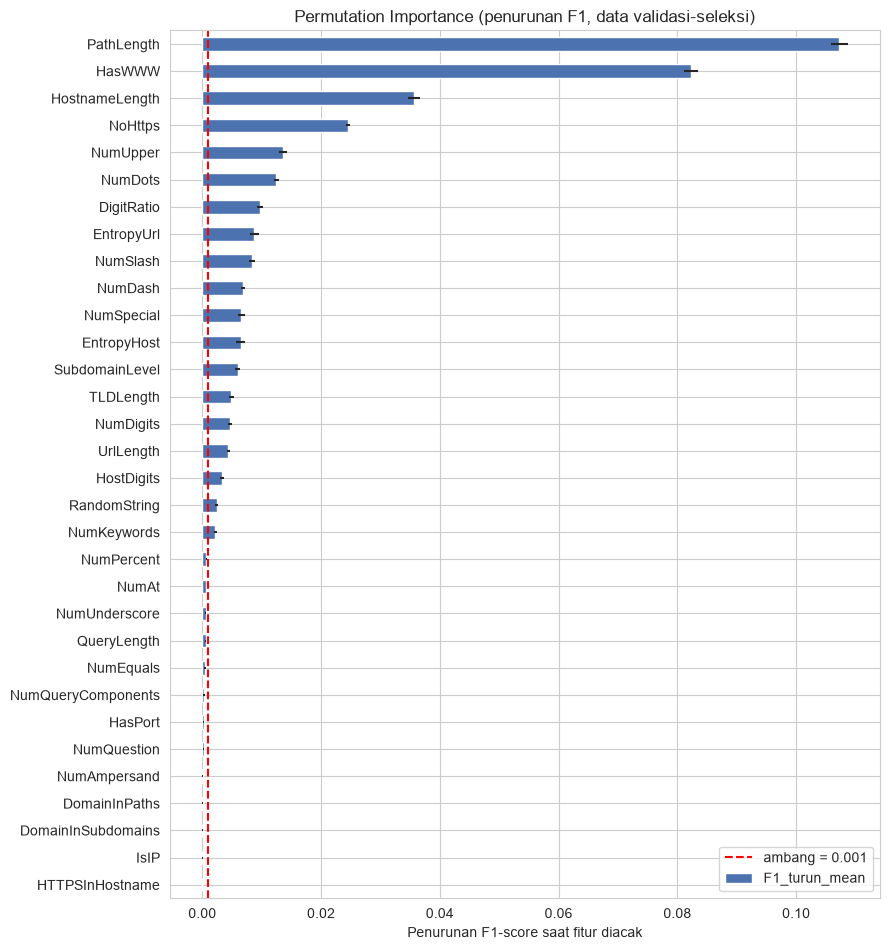


Kandidat fitur tidak berpengaruh (13): ['HTTPSInHostname', 'IsIP', 'DomainInSubdomains', 'DomainInPaths', 'NumAmpersand', 'NumQuestion', 'HasPort', 'NumQueryComponents', 'NumEquals', 'QueryLength', 'NumUnderscore', 'NumAt', 'NumPercent']


In [6]:
from sklearn.inspection import permutation_importance

PI_THRESHOLD = 0.001      # penurunan skor < 0,001 (0,1 poin) dianggap tidak berpengaruh
MAX_DROP_F1  = 0.005      # toleransi penurunan F1 validasi terhadap model 32 fitur
MIN_METRIK   = 0.90       # batas minimum metrik
N_SEL        = 150000     # ukuran sampel data latih untuk seleksi fitur
N_PI         = 30000      # ukuran subsampel validasi untuk permutation importance
N_TREES_SEL  = 100        # jumlah pohon model sementara

FULL_FEATURES = list(FEATURE_ORDER)          # 32 fitur

# Indeks data latih utama (identik dengan pembagian utama: random_state & stratify sama)
_idx_train_utama, _ = train_test_split(
    dataset.index, test_size=0.3, random_state=RANDOM_STATE, stratify=dataset["label"]
)
_sel = dataset.loc[_idx_train_utama]
if len(_sel) > N_SEL:
    _sel = _sel.sample(N_SEL, random_state=RANDOM_STATE)

t0 = time.time()
_F = pd.DataFrame([extract_features(u) for u in _sel["url"]], index=_sel.index)[FULL_FEATURES]
_y = _sel["label"]
print(f"Ekstraksi 32 fitur untuk {len(_F):,} URL sampel: {time.time() - t0:.1f} detik")

_Xtr_s, _Xva, _ytr_s, _yva = train_test_split(_F, _y, test_size=0.2, random_state=RANDOM_STATE, stratify=_y)
print("Data latih-seleksi:", _Xtr_s.shape, "| Data validasi-seleksi:", _Xva.shape)

def latih_sementara(cols):
    m = RandomForestClassifier(n_estimators=N_TREES_SEL, max_depth=20, class_weight="balanced",
                               random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(_Xtr_s[cols], _ytr_s)
    return m

def metrik_val(m, cols):
    p = m.predict_proba(_Xva[cols])[:, 1]
    pr = (p >= 0.5).astype(int)
    return {"Accuracy": accuracy_score(_yva, pr), "Precision": precision_score(_yva, pr),
            "Recall": recall_score(_yva, pr), "F1": f1_score(_yva, pr),
            "ROC-AUC": roc_auc_score(_yva, p)}

t0 = time.time()
model_sel = latih_sementara(FULL_FEATURES)
metrik_base = metrik_val(model_sel, FULL_FEATURES)
print(f"Model sementara 32 fitur dilatih dalam {time.time() - t0:.1f} detik")
print("Metrik validasi-seleksi (32 fitur):", {k: round(v, 4) for k, v in metrik_base.items()})

if len(_Xva) > N_PI:
    X_pi, _, y_pi, _ = train_test_split(_Xva, _yva, train_size=N_PI, stratify=_yva, random_state=RANDOM_STATE)
else:
    X_pi, y_pi = _Xva, _yva

t0 = time.time()
pi = permutation_importance(model_sel, X_pi, y_pi, scoring={"f1": "f1", "roc_auc": "roc_auc"},
                            n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
print(f"Permutation importance selesai dalam {time.time() - t0:.1f} detik\n")

pi_df = pd.DataFrame({
    "F1_turun_mean": pi["f1"].importances_mean, "F1_turun_std": pi["f1"].importances_std,
    "AUC_turun_mean": pi["roc_auc"].importances_mean, "AUC_turun_std": pi["roc_auc"].importances_std,
}, index=FULL_FEATURES).sort_values("F1_turun_mean", ascending=False)
print(pi_df.round(5))

fig, ax = plt.subplots(figsize=(9, max(6, 0.3 * len(pi_df))))
pi_df["F1_turun_mean"].iloc[::-1].plot.barh(xerr=pi_df["F1_turun_std"].iloc[::-1], color="#4C72B0", ax=ax)
ax.axvline(PI_THRESHOLD, color="red", ls="--", label=f"ambang = {PI_THRESHOLD}")
ax.set_title("Permutation Importance (penurunan F1, data validasi-seleksi)")
ax.set_xlabel("Penurunan F1-score saat fitur diacak")
ax.legend(); plt.tight_layout(); plt.show()

kandidat = pi_df[(pi_df["F1_turun_mean"] < PI_THRESHOLD) & (pi_df["AUC_turun_mean"] < PI_THRESHOLD)]
kandidat = kandidat.sort_values(["F1_turun_mean", "AUC_turun_mean"]).index.tolist()
print(f"\nKandidat fitur tidak berpengaruh ({len(kandidat)}):", kandidat)

In [7]:
# Binary search: jumlah kandidat terbanyak yang bisa dihapus tanpa menurunkan performa
def lolos(m, cols):
    mt = metrik_val(m, cols)
    ok = (metrik_base["F1"] - mt["F1"] <= MAX_DROP_F1) and \
         all(v >= MIN_METRIK or metrik_base[k] < MIN_METRIK for k, v in mt.items())
    return ok, mt

lo, hi = 0, len(kandidat)
terbaik_cols = FULL_FEATURES
log = []
while lo < hi:
    mid = (lo + hi + 1) // 2
    cols = [f for f in FULL_FEATURES if f not in kandidat[:mid]]
    m = latih_sementara(cols)
    ok, mt = lolos(m, cols)
    log.append({"hapus": mid, "sisa_fitur": len(cols), "lolos": ok,
                "F1": round(mt["F1"], 4), "ROC-AUC": round(mt["ROC-AUC"], 4)})
    if ok:
        lo, terbaik_cols = mid, cols
    else:
        hi = mid - 1

print("Log pencarian:")
print(pd.DataFrame(log).to_string(index=False) if log else "(tidak ada kandidat)")

Log pencarian:
 hapus  sisa_fitur  lolos     F1  ROC-AUC
     7          25   True 0.9422   0.9883
    10          22   True 0.9416   0.9883
    12          20   True 0.9407   0.9881
    13          19   True 0.9406   0.9880


In [8]:
# Fitur final yang dipakai di seluruh tahap berikutnya
FEATURE_SELECTED = list(terbaik_cols)
FEATURE_DIHAPUS = [f for f in FULL_FEATURES if f not in FEATURE_SELECTED]

print(f"Fitur awal    : {len(FULL_FEATURES)}")
print(f"Fitur dihapus : {len(FEATURE_DIHAPUS)} -> {FEATURE_DIHAPUS}")
print(f"Fitur terpilih: {len(FEATURE_SELECTED)} -> {FEATURE_SELECTED}")

m_sel = latih_sementara(FEATURE_SELECTED) if FEATURE_DIHAPUS else model_sel
print("\nMetrik validasi model sementara:")
print(pd.DataFrame({"32 fitur": metrik_base, f"{len(FEATURE_SELECTED)} fitur": metrik_val(m_sel, FEATURE_SELECTED)}).round(4))

pi_df.assign(dihapus=pi_df.index.isin(FEATURE_DIHAPUS)).to_csv("hasil_permutation_importance.csv")
print("\nTabel permutation importance disimpan: hasil_permutation_importance.csv")

Fitur awal    : 32
Fitur dihapus : 13 -> ['NumUnderscore', 'NumPercent', 'NumQueryComponents', 'NumAmpersand', 'DomainInPaths', 'DomainInSubdomains', 'HTTPSInHostname', 'QueryLength', 'NumEquals', 'NumAt', 'NumQuestion', 'IsIP', 'HasPort']
Fitur terpilih: 19 -> ['UrlLength', 'NumDots', 'SubdomainLevel', 'NumDash', 'RandomString', 'NoHttps', 'HostnameLength', 'PathLength', 'NumSlash', 'NumDigits', 'DigitRatio', 'HostDigits', 'NumKeywords', 'EntropyUrl', 'EntropyHost', 'NumSpecial', 'NumUpper', 'HasWWW', 'TLDLength']

Metrik validasi model sementara:
           32 fitur  19 fitur
Accuracy     0.9489    0.9474
Precision    0.9496    0.9460
Recall       0.9347    0.9353
F1           0.9421    0.9406
ROC-AUC      0.9884    0.9880

Tabel permutation importance disimpan: hasil_permutation_importance.csv


In [9]:
# Hanya fitur terpilih (FEATURE_SELECTED) yang disimpan pada data_final.
# Data kini berukuran besar (~450 ribu URL), jadi fitur dikumpulkan sebagai list of dict
# lalu dijadikan DataFrame sekali jalan (hasilnya identik, tetapi jauh lebih cepat
# daripada apply + pd.Series per baris).
feature_df = pd.DataFrame(
    [extract_features(u) for u in dataset["url"]],
    index=dataset.index
)[FEATURE_SELECTED]   # simpan hanya fitur hasil seleksi (permutation importance)
data_final = pd.concat([dataset[["url", "label"]], feature_df], axis=1)

n_missing = data_final.isnull().sum().sum()
print("Ukuran data setelah ekstraksi fitur:", data_final.shape)
print("Jumlah missing value:", n_missing)

# Penanganan eksplisit apabila ekstraksi fitur menghasilkan missing value
# (mis. URL dengan format tidak wajar yang gagal diparsing sebagian).
if n_missing > 0:
    print("\nKolom dengan missing value:")
    print(data_final.isnull().sum()[data_final.isnull().sum() > 0])
    data_final = data_final.dropna().reset_index(drop=True)
    print("\nUkuran data setelah baris ber-missing-value dibuang:", data_final.shape)
else:
    print("Tidak ditemukan missing value pada fitur hasil ekstraksi — data siap digunakan.")

data_final.head()

Ukuran data setelah ekstraksi fitur: (611055, 21)
Jumlah missing value: 0
Tidak ditemukan missing value pada fitur hasil ekstraksi — data siap digunakan.


,url,label,UrlLength,NumDots,SubdomainLevel,NumDash,RandomString,NoHttps,HostnameLength,PathLength,...,NumDigits,DigitRatio,HostDigits,NumKeywords,EntropyUrl,EntropyHost,NumSpecial,NumUpper,HasWWW,TLDLength
0,http://%20%25**)(**@fbrasil.com/old/lqjj0ukuvg...,1,57,1,0,0,0,1,11,26,...,8,0.160000,0,0,4.783465,3.459432,13,0,0,3
1,https://*f003.backblazeb2.com*/file/pesosi/hom...,1,52,3,1,0,0,0,22,22,...,4,0.090909,4,0,4.265583,3.788755,8,0,0,4
2,http://0-docusign-secured-843439-1-srs09.repli...,1,52,2,1,5,0,1,44,1,...,10,0.222222,10,1,4.339091,4.280470,8,0,0,3
3,http://0-olx.1850943.xyz/,1,25,2,1,1,0,1,17,1,...,8,0.444444,8,0,3.836592,3.734522,4,0,0,3
4,http://0.0.0.0forum.cryptonight.net,1,35,5,4,0,1,1,28,0,...,4,0.142857,4,0,3.722907,3.722907,5,0,0,3


### Studi Kasus: Menemukan & Memperbaiki Kebocoran Data (Data Leakage) pada Fitur `NoHttps`

Pada iterasi awal implementasi, fitur `NoHttps` dihitung dengan asumsi sederhana: jika URL tidak menuliskan skema protokol, maka diasumsikan `http` (tidak aman). Pengecekan distribusi fitur ini per sumber data mengungkap masalah serius:

In [10]:
feats_check = dataset["url"].apply(lambda u: 0 if str(u).lower().startswith("https://") else 1)
check_df = dataset.copy()
check_df["NoHttps_naif"] = feats_check
print("Distribusi NoHttps (asumsi naif: skema kosong -> http) per sumber & label:")
print(check_df.groupby(["source", "label"])["NoHttps_naif"].mean().round(3))

Distribusi NoHttps (asumsi naif: skema kosong -> http) per sumber & label:
source     label
Kaggle     0        0.021
           1        0.267
PhishTank  1        0.118
Name: NoHttps_naif, dtype: float64


In [11]:
print("Distribusi NoHttps (setelah perbaikan) per sumber & label:")
if "NoHttps" in data_final.columns:
    print(data_final.join(dataset["source"]).groupby(["source", "label"])["NoHttps"].mean().round(3))
else:
    print("Fitur NoHttps tidak termasuk fitur terpilih.")

Distribusi NoHttps (setelah perbaikan) per sumber & label:
source     label
Kaggle     0        0.021
           1        0.267
PhishTank  1        0.118
Name: NoHttps, dtype: float64


### Korelasi fitur terhadap Label

Korelasi setiap fitur terhadap label:
HasWWW           -0.524
EntropyHost       0.388
HostnameLength    0.383
DigitRatio        0.354
NoHttps           0.347
HostDigits        0.314
NumDigits         0.176
EntropyUrl        0.163
NumKeywords       0.120
RandomString      0.101
SubdomainLevel    0.099
TLDLength         0.094
NumSlash         -0.090
PathLength       -0.086
UrlLength         0.060
NumDots           0.058
NumDash          -0.056
NumUpper          0.050
NumSpecial        0.001
Name: label, dtype: float64


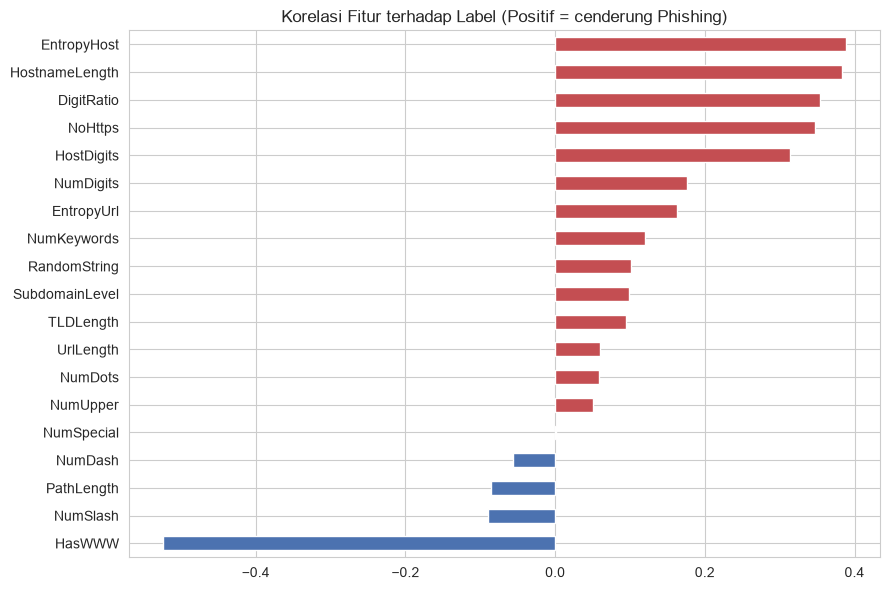

In [12]:
corr = data_final.drop(columns=["url"]).corr()["label"].drop("label").sort_values(key=abs, ascending=False)
print("Korelasi setiap fitur terhadap label:")
print(corr.round(3))

plt.figure(figsize=(9, max(6, 0.3 * len(corr))))
corr.sort_values().plot.barh(color=["#C44E52" if v > 0 else "#4C72B0" for v in corr.sort_values()])
plt.title("Korelasi Fitur terhadap Label (Positif = cenderung Phishing)")
plt.tight_layout()
plt.show()

## Preprocessing, Split Data & Pemodelan Random Forest 

Karena Random Forest bekerja berdasarkan pembagian nilai (threshold split) pada setiap node, normalisasi/scaling fitur tidak diperlukan. Dataset dibagi menjadi 70% data latih, 15% data validasi, dan 15% data uji dengan stratifikasi kelas.

In [13]:
feature_cols = FEATURE_SELECTED   # hasil seleksi fitur (permutation importance)
X = data_final[feature_cols]
y = data_final["label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=RANDOM_STATE, stratify=y_temp
)

print("Data latih   :", X_train.shape)
print("Data validasi:", X_val.shape)
print("Data uji     :", X_test.shape)

ratio = y_train.value_counts(normalize=True)
print("\nRasio kelas pada data latih:\n", ratio.round(3))

Data latih   : (427738, 19)
Data validasi: (91658, 19)
Data uji     : (91659, 19)

Rasio kelas pada data latih:
 label
0    0.555
1    0.445
Name: proportion, dtype: float64


### Koreksi Bias Dataset: Augmentasi Data Latih

Pada dataset gabungan, URL yang hanya berupa nama domain (tanpa path) hampir seluruhnya berlabel phishing (sekitar 99%), dan sebagian besar URL legitimate memiliki path yang dalam. Akibatnya model mempelajari pola dataset ini, sehingga halaman utama situs resmi (mis. `https://untirta.ac.id/`) salah diprediksi phishing. Dua augmentasi berikut hanya dibuat dari **data latih** (data validasi dan uji tidak disentuh):

1. **Halaman utama situs legitimate**: untuk host unik pada data latih berlabel legitimate, dibuat URL `skema://host` dan `skema://host/`, berlabel legitimate. Halaman utama dari domain yang sah tetap sah.
2. **Invarian `www`**: URL legitimate yang memakai `www.` dibuat juga versi tanpa `www.`, dan URL phishing tanpa `www.` dibuat juga versi dengan `www.`. Ada atau tidaknya `www.` tidak mengubah sah atau tidaknya sebuah situs.

Bobot kelas phishing dinaikkan 1,3 kali dari bobot *balanced* agar Recall tidak turun setelah augmentasi.

In [14]:
from urllib.parse import urlparse

PHISHING_WEIGHT_MULT = 1.3

train_urls = data_final.loc[X_train.index, "url"].reset_index(drop=True)
train_labels = y_train.reset_index(drop=True)
train_www = pd.Series([1 if get_hostname(u).startswith("www.") else 0 for u in train_urls])

netloc = np.array([urlparse(u).netloc.lower() for u in train_urls])
scheme = np.array([u.split("://")[0] if "://" in u else "http" for u in train_urls])
is_legit = (train_labels.values == 0)

# (1) Halaman utama dari host legitimate pada data latih
first_scheme = {h: s for h, s in zip(netloc[is_legit], scheme[is_legit])}
hosts_legit_train = np.array(sorted(set(netloc[is_legit])))
rng_aug = np.random.RandomState(0)
sel_hosts = rng_aug.choice(hosts_legit_train, size=min(60000, len(hosts_legit_train)), replace=False)
aug_home_urls = []
for h in sel_hosts:
    s = first_scheme[h]
    aug_home_urls += [f"{s}://{h}", f"{s}://{h}/"]

# (2) Invarian www
tr_df = pd.DataFrame({"url": train_urls, "label": train_labels, "www": train_www})
legit_www = tr_df[(tr_df.label == 0) & (tr_df.www == 1)]
legit_www = legit_www.sample(min(50000, len(legit_www)), random_state=1)["url"]
legit_www_off = legit_www.str.replace("://www.", "://", n=1, regex=False)
phish_nowww = tr_df[(tr_df.label == 1) & (tr_df.www == 0)]
phish_nowww = phish_nowww.sample(min(50000, len(phish_nowww)), random_state=1)["url"]
phish_www_on = phish_nowww.apply(lambda u: u.split("://", 1)[0] + "://www." + u.split("://", 1)[1])

aug_urls = list(aug_home_urls) + list(legit_www_off) + list(phish_www_on)
aug_labels = np.array([0] * (len(aug_home_urls) + len(legit_www_off)) + [1] * len(phish_www_on))
aug_X = pd.DataFrame([extract_features(u) for u in aug_urls])[feature_cols]

X_train_fit = pd.concat([X_train, aug_X], ignore_index=True)
y_train_fit = pd.concat([y_train.reset_index(drop=True), pd.Series(aug_labels)], ignore_index=True)

n_fit = len(y_train_fit); n1 = int(y_train_fit.sum()); n0 = n_fit - n1
class_weight = {0: n_fit / (2 * n0), 1: PHISHING_WEIGHT_MULT * n_fit / (2 * n1)}

print("Data latih asli            :", len(X_train))
print("Augmentasi halaman utama   :", len(aug_home_urls))
print("Augmentasi www (legit/phish):", len(legit_www_off), "/", len(phish_www_on))
print("Total data latih untuk fit :", len(X_train_fit))
print("Rasio kelas setelah augmentasi:\n", y_train_fit.value_counts(normalize=True).round(3))
print("Bobot kelas:", {k: round(v, 3) for k, v in class_weight.items()})

Data latih asli            : 427738
Augmentasi halaman utama   : 106874
Augmentasi www (legit/phish): 50000 / 50000
Total data latih untuk fit : 634612
Rasio kelas setelah augmentasi:
 0    0.621
1    0.379
Name: proportion, dtype: float64
Bobot kelas: {0: 0.805, 1: 1.716}


Pencarian hyperparameter terbaik dilakukan dengan `GridSearchCV` (5-fold cross-validation, metrik F1-score) pada data latih yang sudah ditambah augmentasi. Catatan: skor CV dihitung pada data yang sudah termasuk baris augmentasi (yang lebih sulit), sehingga tidak sebanding langsung dengan metrik pada data uji asli. Skor CV dipakai hanya untuk memilih hyperparameter, sedangkan evaluasi sebenarnya memakai data uji asli di bawah.

**Catatan memori:** pencarian hyperparameter memakai subsampel terstratifikasi (`N_TUNE`) dengan `GridSearchCV(n_jobs=1)` dan Random Forest `n_jobs=-1`, supaya data tidak disalin ke banyak proses (penyebab `MemoryError`). Model dengan parameter terbaik kemudian dilatih ulang pada seluruh data latih. Jika RAM masih tidak cukup, kecilkan `N_TUNE` (mis. 150000).

In [15]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20],
}

# Hemat memori: data dijadikan float32/int8 (format internal Random Forest) agar tidak
# disalin ulang pada setiap fit, dan paralelisme hanya di satu tingkat.
X_fit32 = X_train_fit.astype(np.float32)
y_fit8 = y_train_fit.astype(np.int8)

# Pencarian hyperparameter memakai subsampel terstratifikasi (N_TUNE); model terbaik
# kemudian dilatih ulang pada SELURUH data latih (+ augmentasi).
N_TUNE = 250000
if len(X_fit32) > N_TUNE:
    X_tune, _, y_tune, _ = train_test_split(
        X_fit32, y_fit8, train_size=N_TUNE, stratify=y_fit8, random_state=RANDOM_STATE
    )
else:
    X_tune, y_tune = X_fit32, y_fit8
print(f"Data untuk tuning: {len(X_tune):,} baris | data untuk pelatihan akhir: {len(X_fit32):,} baris")

t0 = time.time()
grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, class_weight=class_weight, n_jobs=-1),
    param_grid, cv=5, scoring="f1",
    n_jobs=1,          # paralel cukup di dalam Random Forest (n_jobs=-1); mencegah MemoryError
    verbose=2,
)
grid.fit(X_tune, y_tune)

print(f"\nWaktu pencarian: {time.time() - t0:.1f} detik")
print("Parameter terbaik:", grid.best_params_)
print("F1-score CV terbaik:", grid.best_score_)

# Latih ulang dengan parameter terbaik pada seluruh data latih
t0 = time.time()
model = RandomForestClassifier(
    **grid.best_params_, random_state=RANDOM_STATE, class_weight=class_weight, n_jobs=-1
)
model.fit(X_fit32, y_fit8)
print(f"Waktu pelatihan akhir: {time.time() - t0:.1f} detik")
model


Data untuk tuning: 250,000 baris | data untuk pelatihan akhir: 634,612 baris
Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV] END .....................max_depth=10, n_estimators=100; total time=  16.0s
[CV] END .....................max_depth=10, n_estimators=100; total time=  14.5s
[CV] END .....................max_depth=10, n_estimators=100; total time=  14.8s
[CV] END .....................max_depth=10, n_estimators=100; total time=  15.5s
[CV] END .....................max_depth=10, n_estimators=100; total time=  16.8s
[CV] END .....................max_depth=10, n_estimators=200; total time=  35.4s
[CV] END .....................max_depth=10, n_estimators=200; total time=  33.9s
[CV] END .....................max_depth=10, n_estimators=200; total time=  35.5s
[CV] END .....................max_depth=10, n_estimators=200; total time=  29.7s
[CV] END .....................max_depth=10, n_estimators=200; total time=  31.7s
[CV] END .....................max_depth=20, n_estimat

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{0: 0.8048834932246985, 1: 1.7159809639496475}"
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best s

In [16]:
hasil_grid = pd.DataFrame(grid.cv_results_)[
    ["param_n_estimators", "param_max_depth", "mean_test_score", "std_test_score", "rank_test_score"]
]
print(hasil_grid.round(4).to_string(index=False))

 param_n_estimators  param_max_depth  mean_test_score  std_test_score  rank_test_score
                100               10           0.8699          0.0016                4
                200               10           0.8701          0.0015                3
                100               20           0.8956          0.0013                2
                200               20           0.8959          0.0017                1


### Verifikasi Perhitungan Manual Random Forest *(Persamaan 1, Sub-bab 4.3.4)*

Probabilitas akhir Random Forest adalah rata-rata probabilitas seluruh pohon. Sel berikut menghitung rata-rata itu secara manual dan membandingkannya dengan `predict_proba()`.

In [17]:
# Sampel uji
sample_url = "https://www.bbc.com/news"
x_row = pd.DataFrame([extract_features(sample_url)])[feature_cols]

# Mengambil prediksi probabilitas dari setiap pohon secara individual
tree_probas = np.array([tree.predict_proba(x_row)[0] for tree in model.estimators_])

# Menghitung rata-rata manual sesuai Persamaan (1)
manual_avg = tree_probas.mean(axis=0)

print(manual_avg)                                              # [P(Legitimate), P(Phishing)]
print(model.predict_proba(x_row)[0])                            # nilainya harus sama dengan baris di atas
print(np.allclose(manual_avg, model.predict_proba(x_row)[0]))   # harus True

print("\nProbabilitas kelas Phishing dari 10 pohon pertama:")
for i in range(10):
    print(f"  Pohon {i+1:>3}: {tree_probas[i][1]:.4f}")

[0.92698157 0.07301843]
[0.92698157 0.07301843]
True

Probabilitas kelas Phishing dari 10 pohon pertama:
  Pohon   1: 0.0854
  Pohon   2: 0.0158
  Pohon   3: 0.0798
  Pohon   4: 0.0094
  Pohon   5: 0.0000
  Pohon   6: 0.0000
  Pohon   7: 0.0122
  Pohon   8: 0.0424
  Pohon   9: 0.1438
  Pohon  10: 0.1523


In [18]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"ROC-AUC   : {auc:.4f}")
print("\n" + classification_report(y_test, y_pred, target_names=["Legitimate", "Phishing"]))

Accuracy  : 0.9400
Precision : 0.9533
Recall    : 0.9097
F1-score  : 0.9310
ROC-AUC   : 0.9852

              precision    recall  f1-score   support

  Legitimate       0.93      0.96      0.95     50861
    Phishing       0.95      0.91      0.93     40798

    accuracy                           0.94     91659
   macro avg       0.94      0.94      0.94     91659
weighted avg       0.94      0.94      0.94     91659



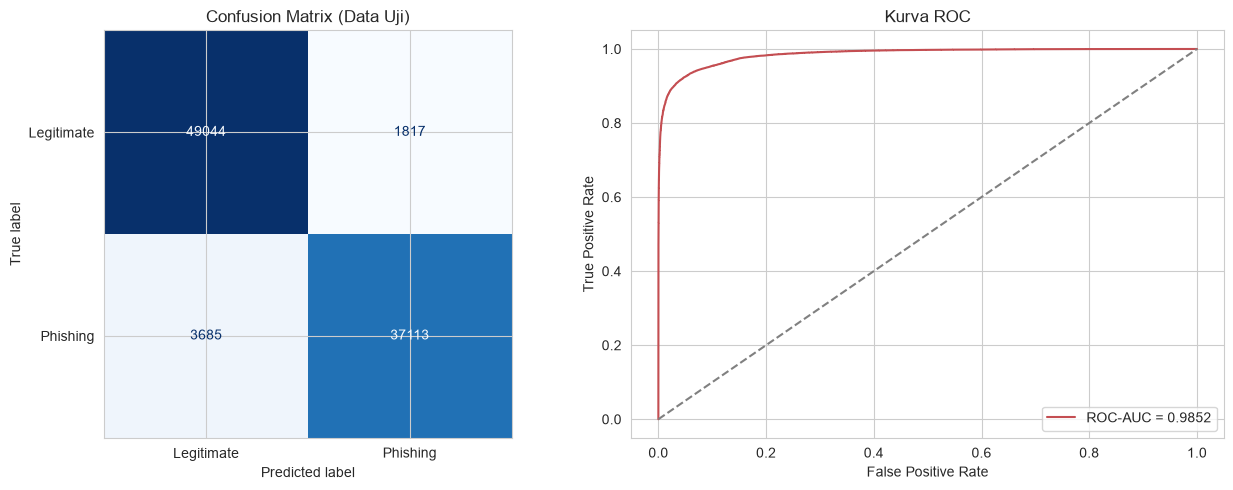

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Legitimate", "Phishing"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix (Data Uji)")

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, label=f"ROC-AUC = {auc:.4f}", color="#C44E52")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Kurva ROC"); axes[1].legend()

plt.tight_layout()
plt.show()

### Pengecekan Overfitting *(Perbandingan Data Latih, Validasi, dan Uji)*

Overfitting terjadi ketika performa pada data latih jauh lebih tinggi daripada data yang belum pernah dilihat model. Karena itu metrik dihitung pada ketiga subset. Selisih kecil (kurang dari sekitar 0,05) menandakan model menggeneralisasi dengan baik, sedangkan selisih besar menandakan model menghafal data latih. Ambang 0,05 adalah patokan praktis, bukan aturan baku.

In [20]:
def hitung_metrik(X_, y_, threshold=0.5):
    p = model.predict_proba(X_)[:, 1]
    pr = (p >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_, pr),
        "Precision": precision_score(y_, pr),
        "Recall": recall_score(y_, pr),
        "F1-score": f1_score(y_, pr),
        "ROC-AUC": roc_auc_score(y_, p),
    }

hasil_split = pd.DataFrame({
    "Latih": hitung_metrik(X_train, y_train),
    "Validasi": hitung_metrik(X_val, y_val),
    "Uji": hitung_metrik(X_test, y_test),
}).T
print(hasil_split.round(4))

selisih = (hasil_split.loc["Latih"] - hasil_split.loc["Uji"]).round(4)
print("\nSelisih (Latih - Uji):")
print(selisih)
print("\nF1 CV terbaik GridSearchCV (termasuk baris augmentasi, tidak sebanding langsung dengan data uji):", round(grid.best_score_, 4))

if selisih.max() > 0.05:
    print("\n>>> Selisih > 0,05 pada sedikitnya satu metrik: ada indikasi overfitting.")
    print("    Pertimbangkan max_depth lebih kecil atau min_samples_leaf lebih besar.")
else:
    print("\n>>> Selisih seluruh metrik <= 0,05: tidak ada indikasi overfitting yang berarti.")

          Accuracy  Precision  Recall  F1-score  ROC-AUC
Latih       0.9660     0.9847  0.9382    0.9609   0.9940
Validasi    0.9427     0.9563  0.9129    0.9341   0.9856
Uji         0.9400     0.9533  0.9097    0.9310   0.9852

Selisih (Latih - Uji):
Accuracy     0.0260
Precision    0.0314
Recall       0.0285
F1-score     0.0299
ROC-AUC      0.0088
dtype: float64

F1 CV terbaik GridSearchCV (termasuk baris augmentasi, tidak sebanding langsung dengan data uji): 0.8959

>>> Selisih seluruh metrik <= 0,05: tidak ada indikasi overfitting yang berarti.


### Analisis False Positive (FP) dan False Negative (FN)

- **FP**: URL *legitimate* yang salah diprediksi *phishing* (pengguna terganggu).
- **FN**: URL *phishing* yang lolos diprediksi *legitimate* (lebih berbahaya).

Sel berikut menghitung tingkat FP dan FN, sebarannya per sumber data, contoh URL yang salah, dan perbandingan rata-rata nilai fitur antara URL yang benar dan yang salah.

In [21]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"TN = {tn:,} | FP = {fp:,} | FN = {fn:,} | TP = {tp:,}")
print(f"False Positive Rate (FPR) = FP / (FP + TN) = {fp / (fp + tn):.4f}")
print(f"False Negative Rate (FNR) = FN / (FN + TP) = {fn / (fn + tp):.4f}")

err = data_final.loc[X_test.index, ["url", "label"]].join(dataset["source"])
err["pred"] = y_pred
err["proba_phishing"] = y_proba
err["jenis"] = np.select(
    [(err["label"] == 0) & (err["pred"] == 1), (err["label"] == 1) & (err["pred"] == 0)],
    ["FP", "FN"], default="Benar"
)

print("\nJumlah kesalahan per sumber data:")
print(pd.crosstab(err["source"], err["jenis"]))

print("\nTingkat kesalahan per sumber & label asli:")
print(err.groupby(["source", "label"])["jenis"].apply(lambda s: (s != "Benar").mean()).round(4))

print("\n10 contoh FN (phishing lolos):")
print(err[err["jenis"] == "FN"].sample(10, random_state=RANDOM_STATE)[["url", "proba_phishing"]].to_string(index=False))
print("\n10 contoh FP (legitimate dikira phishing):")
print(err[err["jenis"] == "FP"].sample(10, random_state=RANDOM_STATE)[["url", "proba_phishing"]].to_string(index=False))

print("\nRata-rata nilai fitur menurut jenis prediksi (Benar / FP / FN):")
print(X_test.assign(jenis=err["jenis"]).groupby("jenis")[feature_cols].mean().T.round(3))

TN = 49,044 | FP = 1,817 | FN = 3,685 | TP = 37,113
False Positive Rate (FPR) = FP / (FP + TN) = 0.0357
False Negative Rate (FNR) = FN / (FN + TP) = 0.0903

Jumlah kesalahan per sumber data:
jenis      Benar    FN    FP
source                      
Kaggle     81890  3374  1817
PhishTank   4267   311     0

Tingkat kesalahan per sumber & label asli:
source     label
Kaggle     0        0.0357
           1        0.0932
PhishTank  1        0.0679
Name: jenis, dtype: float64

10 contoh FN (phishing lolos):
                                                                                                  url  proba_phishing
                                                                       https://c-vital.info/index.php        0.395814
                                                         https://cocorost-556.jp/monk/nonccvcxse.html        0.334808
                                                                https://findmydevice.ink/isignesp.php        0.291237
                   

### Uji Generalisasi: Halaman Utama Situs Legitimate pada Host Baru

Data uji asli memiliki pola yang sama dengan data latih, sehingga tidak cukup untuk mendeteksi bias pola dataset. Sel berikut membuat URL halaman utama dari host legitimate pada data uji yang **tidak pernah muncul** di data latih, lalu mengukur berapa yang diprediksi legitimate. Sel ini juga mengukur Recall pada URL phishing yang tanpa path (atau hanya `/`), untuk melihat harga yang dibayar dari koreksi bias.

In [22]:
test_urls_all = data_final.loc[X_test.index, "url"]
test_hosts_legit = {urlparse(u).netloc.lower() for u in test_urls_all[y_test == 0]}
hosts_baru = sorted(test_hosts_legit - set(netloc[is_legit]))
print("Host legitimate pada data uji yang tidak ada di data latih:", len(hosts_baru))

rng_g = np.random.RandomState(0)
sel_baru = rng_g.choice(hosts_baru, size=min(5000, len(hosts_baru)), replace=False)
home_urls = [f"https://{h}" for h in sel_baru] + [f"https://{h}/" for h in sel_baru]
home_X = pd.DataFrame([extract_features(u) for u in home_urls])[feature_cols]
home_pred = model.predict(home_X)
print(f"Halaman utama legitimate (host baru, n={len(home_urls)}): "
      f"diprediksi legitimate = {(home_pred == 0).mean():.3f}")

mask_ph = (y_test.values == 1) & (np.array([len(urlparse(u if "://" in u else "http://" + u).path) for u in test_urls_all]) <= 1)
print(f"Phishing tanpa path / hanya '/' pada data uji (n={mask_ph.sum()}): "
      f"Recall = {(y_pred[mask_ph] == 1).mean():.3f}")

Host legitimate pada data uji yang tidak ada di data latih: 2698


Halaman utama legitimate (host baru, n=5396): diprediksi legitimate = 0.797
Phishing tanpa path / hanya '/' pada data uji (n=19187): Recall = 0.904


### Verifikasi Manual Metrik Evaluasi *(Persamaan 4-7, Sub-bab 4.5.1)*

In [23]:
# Verifikasi manual metrik evaluasi (Persamaan 4-7, Tabel 12 pada Bab IV)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"TN = {tn:,} | FP = {fp:,} | FN = {fn:,} | TP = {tp:,} | total = {tn+fp+fn+tp:,}")

acc_m  = (tp + tn) / (tp + tn + fp + fn)
prec_m = tp / (tp + fp)
rec_m  = tp / (tp + fn)
f1_m   = 2 * prec_m * rec_m / (prec_m + rec_m)

print(f"Accuracy  manual = {acc_m:.4f} | sklearn = {acc:.4f}")
print(f"Precision manual = {prec_m:.4f} | sklearn = {prec:.4f}")
print(f"Recall    manual = {rec_m:.4f} | sklearn = {rec:.4f}")
print(f"F1-score  manual = {f1_m:.4f} | sklearn = {f1:.4f}")
assert np.allclose([acc_m, prec_m, rec_m, f1_m], [acc, prec, rec, f1]), "Metrik manual tidak sama dengan sklearn"
print("Keempat metrik manual identik dengan sklearn.")


TN = 49,044 | FP = 1,817 | FN = 3,685 | TP = 37,113 | total = 91,659
Accuracy  manual = 0.9400 | sklearn = 0.9400
Precision manual = 0.9533 | sklearn = 0.9533
Recall    manual = 0.9097 | sklearn = 0.9097
F1-score  manual = 0.9310 | sklearn = 0.9310
Keempat metrik manual identik dengan sklearn.


### Evaluasi terhadap Kriteria Minimum *(Keputusan Iterasi Modelling)*

Sesuai alur *Modelling & Evaluation* pada metodologi penelitian, hasil evaluasi model dibandingkan terhadap kriteria performa minimum yang ditetapkan. Jika kriteria belum terpenuhi, proses **kembali ke tahap Grid Search/Modelling** (mis. memperluas `param_grid`, menambah data, atau merekayasa ulang fitur) sebelum berlanjut ke tahap interpretasi dan deployment.

In [24]:
# Kriteria performa minimum yang ditetapkan pada penelitian ini
MIN_ACCURACY = 0.90
MIN_F1 = 0.90
MIN_AUC = 0.90

criteria = {
    "Accuracy": (acc, MIN_ACCURACY),
    "F1-score": (f1, MIN_F1),
    "ROC-AUC": (auc, MIN_AUC),
}

print("=== Pengecekan Kriteria Minimum Model ===")
all_passed = True
for metric_name, (value, threshold) in criteria.items():
    status = "LOLOS" if value >= threshold else "BELUM LOLOS"
    if value < threshold:
        all_passed = False
    print(f"{metric_name:10s}: {value:.4f}  (minimum {threshold:.2f}) -> {status}")

if all_passed:
    print("\n>>> Model memenuhi seluruh kriteria minimum. Lanjut ke tahap Interpretation (SHAP).")
else:
    print("\n>>> Model BELUM memenuhi seluruh kriteria minimum.")
    print(">>> Sesuai alur penelitian, proses perlu KEMBALI ke tahap Modelling:")
    print("    - Perluas param_grid pada GridSearchCV, dan/atau")
    print("    - Tambah/kaya-kan fitur atau volume data latih, dan/atau")
    print("    - Evaluasi ulang kualitas data (lihat Bagian 4).")

=== Pengecekan Kriteria Minimum Model ===
Accuracy  : 0.9400  (minimum 0.90) -> LOLOS
F1-score  : 0.9310  (minimum 0.90) -> LOLOS
ROC-AUC   : 0.9852  (minimum 0.90) -> LOLOS

>>> Model memenuhi seluruh kriteria minimum. Lanjut ke tahap Interpretation (SHAP).


> **Tujuan 1 tercapai:** model Random Forest berhasil dibangun dengan performa tinggi pada data uji (F1-score & ROC-AUC ditampilkan di atas), menggunakan fitur-fitur leksikal, struktural, dan indikator keamanan URL yang telah dianalisis pada Bagian 4.

## Interpretasi Model dengan SHAP 

Karena Random Forest bersifat *black-box*, teknik **SHAP (SHapley Additive exPlanations)** diterapkan untuk menjelaskan kontribusi setiap fitur terhadap prediksi model, baik secara **global** (pola umum model) maupun **lokal** (penjelasan untuk satu URL spesifik).

In [25]:
explainer = shap.TreeExplainer(model)

X_sample = X_test.sample(n=200, random_state=RANDOM_STATE)
shap_values = explainer.shap_values(X_sample)

if isinstance(shap_values, list):
    shap_values_phishing = shap_values[1]
else:
    shap_values_phishing = shap_values[:, :, 1]

# Nilai dasar (base value / expected value) untuk kelas Phishing (1)
base_value = (
    explainer.expected_value[1]
    if isinstance(explainer.expected_value, (list, np.ndarray))
    else explainer.expected_value
)

# Objek shap.Explanation (API modern) — dipakai untuk seluruh plot pada bagian ini
shap_explanation = shap.Explanation(
    values=shap_values_phishing,
    base_values=np.repeat(base_value, X_sample.shape[0]),
    data=X_sample.values,
    feature_names=feature_cols,
)

print("Jumlah sampel untuk interpretasi SHAP :", X_sample.shape[0])
print("Bentuk (shape) SHAP values            :", shap_values_phishing.shape)
print("Base value (expected value) kelas Phishing:", round(float(base_value), 4))

Jumlah sampel untuk interpretasi SHAP : 200
Bentuk (shape) SHAP values            : (200, 19)
Base value (expected value) kelas Phishing: 0.5652


### Verifikasi Manual Nilai Shapley dan Additivity *(Persamaan 2-3, Sub-bab 4.4)*

Sel pertama menghitung nilai Shapley contoh 3 fitur (Tabel 8 dan 9 pada Bab IV) secara brute-force. Sel kedua memeriksa sifat additivity SHAP pada model sebenarnya (Tabel 10 pada Bab IV).

In [26]:
# Simulasi Shapley 3 fitur hipotetis {A, B, C} (Tabel 8 -> Tabel 9 pada Bab IV)
from itertools import combinations
from math import factorial

val = {
    frozenset(): 0.50,
    frozenset("A"): 0.60, frozenset("B"): 0.55, frozenset("C"): 0.52,
    frozenset("AB"): 0.68, frozenset("AC"): 0.64, frozenset("BC"): 0.58,
    frozenset("ABC"): 0.70,
}
players = ["A", "B", "C"]
p = len(players)

def shapley(i):
    others = [x for x in players if x != i]
    total = 0.0
    for r in range(len(others) + 1):
        for S in combinations(others, r):
            S = frozenset(S)
            w = factorial(len(S)) * factorial(p - len(S) - 1) / factorial(p)
            total += w * (val[S | {i}] - val[S])
    return total

phi = {i: shapley(i) for i in players}
for i in players:
    print(f"phi_{i} = {phi[i]:.4f}")
print(f"Total = {sum(phi.values()):.4f}  |  Val(ABC) - Val(kosong) = {val[frozenset('ABC')] - val[frozenset()]:.4f}")
assert abs(sum(phi.values()) - (val[frozenset('ABC')] - val[frozenset()])) < 1e-9


phi_A = 0.1150
phi_B = 0.0600
phi_C = 0.0250
Total = 0.2000  |  Val(ABC) - Val(kosong) = 0.2000


In [27]:
# Verifikasi additivity SHAP pada model sebenarnya (Persamaan 3, Tabel 10 pada Bab IV)
url_add = "https://www.bbc.com/news"
feats_add = extract_features(url_add)
X_add = pd.DataFrame([feats_add])[feature_cols]

sv_add = explainer.shap_values(X_add)
sv_add_phish = sv_add[1][0] if isinstance(sv_add, list) else sv_add[:, :, 1][0]
base_add = (explainer.expected_value[1]
            if isinstance(explainer.expected_value, (list, np.ndarray))
            else explainer.expected_value)

tabel10 = (pd.DataFrame({"Nilai x": [feats_add[f] for f in feature_cols], "phi_i (SHAP)": sv_add_phish},
                        index=feature_cols)
           .sort_values("phi_i (SHAP)", key=np.abs, ascending=False))
print(tabel10.round(5))

total_add = float(base_add) + float(sv_add_phish.sum())
proba_add = float(model.predict_proba(X_add)[0, 1])
print(f"\nphi_0 (base value)      = {float(base_add):.4f}")
print(f"phi_0 + sum(phi_i)      = {total_add:.6f}")
print(f"predict_proba (phishing) = {proba_add:.6f}")
assert abs(total_add - proba_add) < 1e-6, "Additivity SHAP tidak terpenuhi"
print("Additivity terpenuhi: base value + total SHAP = probabilitas prediksi model.")


                 Nilai x  phi_i (SHAP)
HostnameLength  11.00000      -0.12493
HasWWW           1.00000      -0.10852
EntropyHost      2.48171      -0.05636
DigitRatio       0.00000      -0.04751
NumDigits        0.00000      -0.04511
NumUpper         0.00000      -0.04247
NoHttps          0.00000      -0.02967
EntropyUrl       3.12500      -0.02405
PathLength       5.00000       0.01621
UrlLength       24.00000       0.01496
SubdomainLevel   1.00000      -0.01401
HostDigits       0.00000      -0.01280
NumDash          0.00000      -0.01037
NumDots          2.00000      -0.00956
RandomString     0.00000      -0.00949
NumSpecial       3.00000       0.00821
NumSlash         1.00000       0.00815
TLDLength        3.00000      -0.00293
NumKeywords      0.00000      -0.00192

phi_0 (base value)      = 0.5652
phi_0 + sum(phi_i)      = 0.073018
predict_proba (phishing) = 0.073018
Additivity terpenuhi: base value + total SHAP = probabilitas prediksi model.


### 6.1 Interpretasi Global

Interpretasi global menjelaskan pola umum yang dipelajari model Random Forest di seluruh data — fitur apa yang paling berpengaruh, dan ke arah mana (mendorong prediksi ke *Phishing* atau ke *Legitimate*). Tiga visualisasi digunakan agar interpretasi global dapat dibaca dari beberapa sudut pandang: **ringkasan global**, **peringkat kepentingan fitur (bar)**, dan **distribusi kontribusi tiap fitur (beeswarm)**.

**SHAP Summary Plot (Global)** — ringkasan menyeluruh yang memetakan setiap fitur ke sebaran nilai SHAP-nya pada seluruh sampel uji; titik-titik diwarnai berdasarkan nilai fitur aslinya (merah = nilai fitur tinggi, biru = nilai fitur rendah), sehingga terlihat baik kepentingan maupun arah pengaruh tiap fitur dalam satu tampilan.

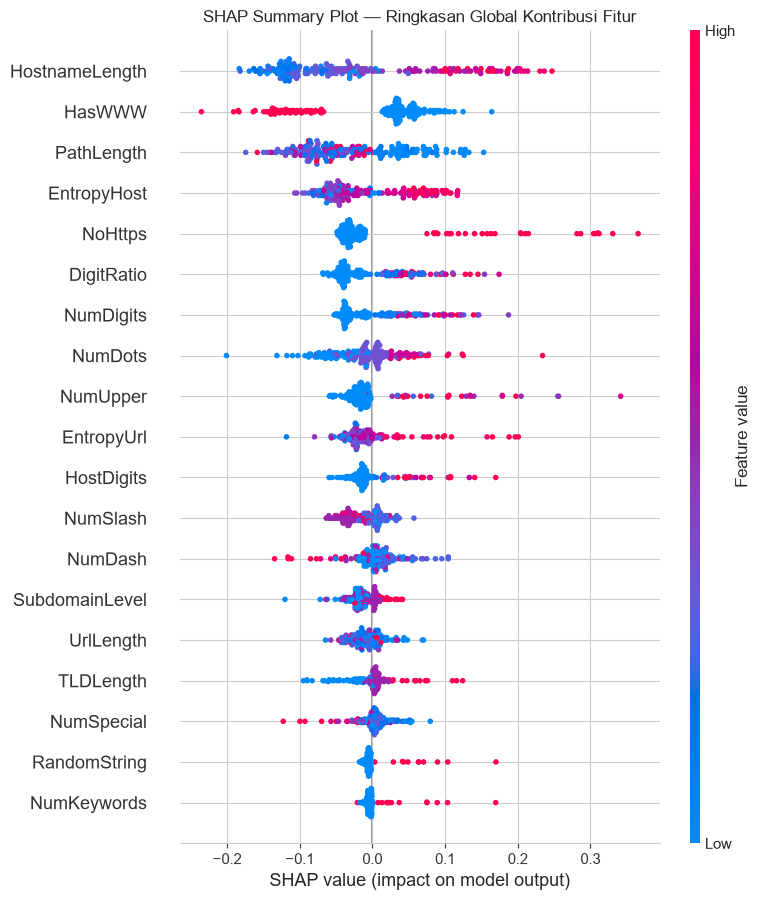

In [28]:
plt.figure(figsize=(9, max(7, 0.3 * len(feature_cols))))
shap.summary_plot(shap_values_phishing, X_sample, plot_type="dot", max_display=len(feature_cols), show=False)
plt.title("SHAP Summary Plot — Ringkasan Global Kontribusi Fitur")
plt.tight_layout()
plt.show()

**SHAP Bar Plot (Mean |SHAP Value|)** — rata-rata besaran (magnitude) kontribusi absolut tiap fitur terhadap prediksi, tanpa memandang arah pengaruhnya. Semakin panjang batang, semakin besar pengaruh fitur tersebut secara rata-rata terhadap keputusan model.

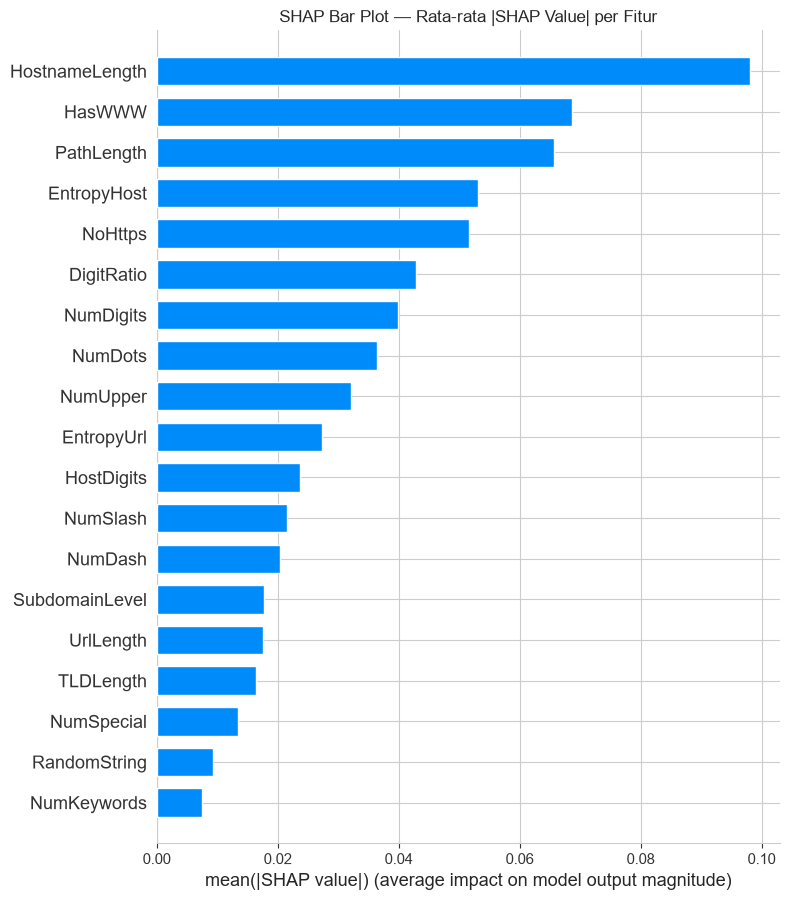

Peringkat fitur berdasarkan rata-rata |SHAP value|:
HostnameLength    0.0981
HasWWW            0.0686
PathLength        0.0658
EntropyHost       0.0531
NoHttps           0.0516
DigitRatio        0.0429
NumDigits         0.0399
NumDots           0.0364
NumUpper          0.0322
EntropyUrl        0.0273
HostDigits        0.0237
NumSlash          0.0215
NumDash           0.0204
SubdomainLevel    0.0177
UrlLength         0.0176
TLDLength         0.0163
NumSpecial        0.0134
RandomString      0.0094
NumKeywords       0.0075
Name: Mean |SHAP Value|, dtype: float64


In [29]:
plt.figure(figsize=(9, max(7, 0.3 * len(feature_cols))))
shap.summary_plot(shap_values_phishing, X_sample, plot_type="bar", max_display=len(feature_cols), show=False)
plt.title("SHAP Bar Plot — Rata-rata |SHAP Value| per Fitur")
plt.tight_layout()
plt.show()

mean_abs_shap = (
    pd.Series(np.abs(shap_values_phishing).mean(axis=0), index=feature_cols)
    .sort_values(ascending=False)
    .rename("Mean |SHAP Value|")
)
print("Peringkat fitur berdasarkan rata-rata |SHAP value|:")
print(mean_abs_shap.round(4))

**SHAP Beeswarm Plot** — variasi dari summary plot yang menonjolkan kepadatan (density) sebaran nilai SHAP tiap fitur; setiap titik mewakili satu sampel URL, posisinya menunjukkan besar & arah kontribusi (kiri = mendorong ke *Legitimate*, kanan = mendorong ke *Phishing*), sedangkan warna tetap merepresentasikan nilai fitur aslinya.

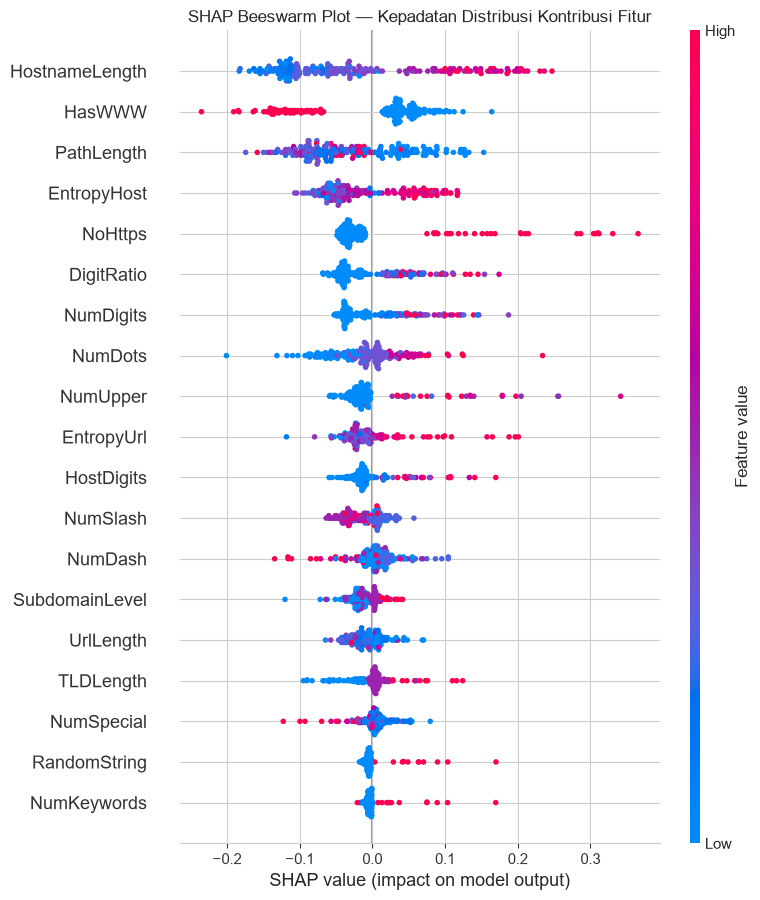

In [30]:
plt.figure(figsize=(9, max(7, 0.3 * len(feature_cols))))
shap.plots.beeswarm(shap_explanation, max_display=len(feature_cols), show=False)
plt.title("SHAP Beeswarm Plot — Kepadatan Distribusi Kontribusi Fitur")
plt.tight_layout()
plt.show()

### Interpretasi Lokal

**SHAP Waterfall Plot (Per Sampel)** — menjelaskan kontribusi tiap fitur untuk **satu prediksi spesifik**, menjawab pertanyaan *"kenapa URL ini diprediksi sebagai phishing (atau legitimate)?"* secara transparan. Agar interpretasi lokal lebih representatif, waterfall plot ditampilkan untuk **beberapa sampel berbeda**: satu URL *Phishing* yang diprediksi benar, satu URL *Legitimate* yang diprediksi benar, dan (jika tersedia) satu sampel yang **salah diprediksi** (misklasifikasi) sebagai bahan evaluasi kritis model.

Kasus       : Legitimate
URL         : https://www.bbc.com/news
Label asli  : Legitimate
Prediksi    : Legitimate  (P(Phishing) = 0.0730)


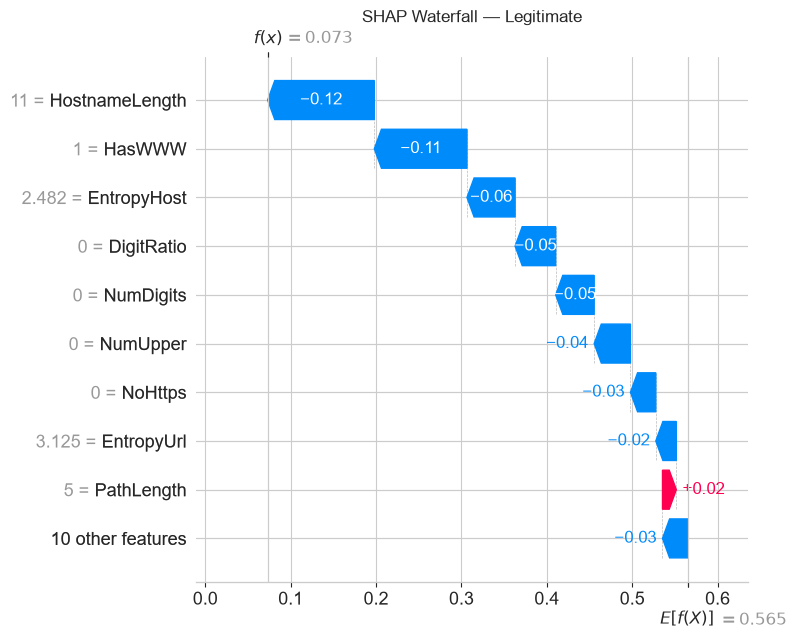

In [31]:
# Studi Kasus: Interpretasi Lokal untuk URL di luar dataset — https://www.bbc.com/news
# (Contoh pengujian model terhadap URL populer/legitimate yang tidak ada di data latih/uji)

target_url = "https://www.bbc.com/news"

# Ekstraksi fitur & prediksi
feats_bbc = extract_features(target_url)
X_bbc = pd.DataFrame([feats_bbc])[feature_cols]

pred_bbc = int(model.predict(X_bbc)[0])
proba_bbc = float(model.predict_proba(X_bbc)[0, 1])
pred_label = "Phishing" if pred_bbc == 1 else "Legitimate"

# Cek apakah URL ini memang ada di dataset (untuk label asli/ground truth)
match_bbc = dataset[dataset["url"] == target_url.lower()]
actual_label = (
    "Phishing" if (not match_bbc.empty and match_bbc["label"].iloc[0] == 1)
    else "Legitimate" if not match_bbc.empty
    else "Tidak ada pada dataset (diketahui legitimate secara umum)"
)

# Hitung nilai SHAP untuk URL ini
sv_bbc = explainer.shap_values(X_bbc)
sv_bbc_phishing = sv_bbc[1][0] if isinstance(sv_bbc, list) else sv_bbc[:, :, 1][0]

print("=" * 70)
print(f"Kasus       : {pred_label}")
print(f"URL         : {target_url}")
print(f"Label asli  : {actual_label}")
print(f"Prediksi    : {pred_label}  (P(Phishing) = {proba_bbc:.4f})")

expl_bbc = shap.Explanation(
    values=sv_bbc_phishing,
    base_values=base_value,
    data=X_bbc.iloc[0].values,
    feature_names=feature_cols,
)

plt.figure()
shap.plots.waterfall(expl_bbc, show=False)
plt.title(f"SHAP Waterfall — {pred_label}")
plt.tight_layout()
plt.show()

URL          : https://vxsx3456543.weebly.com/
Label asli   : Phishing
Prediksi     : Phishing  (P(Phishing) = 0.9998)

Kontribusi SHAP per fitur (diurutkan dari paling berpengaruh):
  HostDigits          : nilai=7      SHAP=+0.1182  -> Phishing
  EntropyHost         : nilai=3.9139770731827506 SHAP=+0.0680  -> Phishing
  HostnameLength      : nilai=22     SHAP=+0.0635  -> Phishing
  DigitRatio          : nilai=0.30434782608695654 SHAP=+0.0560  -> Phishing
  NumDigits           : nilai=7      SHAP=+0.0485  -> Phishing
  HasWWW              : nilai=0      SHAP=+0.0480  -> Phishing
  PathLength          : nilai=1      SHAP=+0.0403  -> Phishing
  NoHttps             : nilai=0      SHAP=-0.0138  -> Legitimate
  NumSlash            : nilai=1      SHAP=+0.0103  -> Phishing
  EntropyUrl          : nilai=4.001822825622231 SHAP=-0.0097  -> Legitimate
  NumUpper            : nilai=0      SHAP=-0.0087  -> Legitimate
  NumDots             : nilai=2      SHAP=+0.0081  -> Phishing
  NumSpecial       

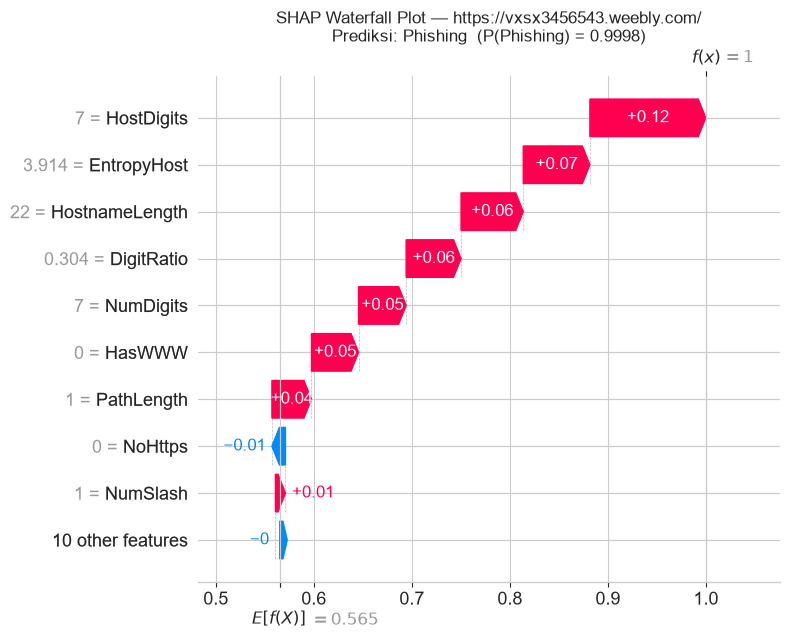

In [32]:
# 6.2 Interpretasi Lokal — Studi Kasus: URL Phishing Spesifik
# Waterfall Plot menelusuri kontribusi tiap fitur dari base value hingga
# probabilitas akhir prediksi, untuk satu sampel URL tertentu.

target_url = "https://vxsx3456543.weebly.com/"

# Ekstraksi fitur & prediksi untuk URL contoh
feats_local = extract_features(target_url)
X_local = pd.DataFrame([feats_local])[feature_cols]

pred_local = int(model.predict(X_local)[0])
proba_local = float(model.predict_proba(X_local)[0, 1])
label_local = "Phishing" if pred_local == 1 else "Legitimate"

# Cari label asli (ground truth) apabila URL ini memang berasal dari dataset penelitian
match = dataset[dataset["url"] == target_url.lower()]
actual_label = "Phishing" if (not match.empty and match["label"].iloc[0] == 1) else (
    "Legitimate" if not match.empty else "Tidak ditemukan pada dataset"
)

print("=" * 70)
print(f"URL          : {target_url}")
print(f"Label asli   : {actual_label}")
print(f"Prediksi     : {label_local}  (P(Phishing) = {proba_local:.4f})")

# Hitung nilai SHAP untuk sampel tunggal ini
sv_local = explainer.shap_values(X_local)
sv_local_phishing = sv_local[1][0] if isinstance(sv_local, list) else sv_local[:, :, 1][0]

base_value_local = (
    explainer.expected_value[1]
    if isinstance(explainer.expected_value, (list, np.ndarray))
    else explainer.expected_value
)

expl_local = shap.Explanation(
    values=sv_local_phishing,
    base_values=base_value_local,
    data=X_local.iloc[0].values,
    feature_names=feature_cols,
)

# Rincian kontribusi tiap fitur, diurutkan dari yang paling berpengaruh
contrib_local = (
    pd.Series(sv_local_phishing, index=feature_cols)
    .sort_values(key=np.abs, ascending=False)
)
print("\nKontribusi SHAP per fitur (diurutkan dari paling berpengaruh):")
for fname, shap_val in contrib_local.items():
    arah = "-> Phishing" if shap_val > 0 else "-> Legitimate"
    print(f"  {fname:20s}: nilai={feats_local[fname]:<6} SHAP={shap_val:+.4f}  {arah}")

# Visualisasi Waterfall Plot (Gambar 10)
plt.figure(figsize=(9, 6))
shap.plots.waterfall(expl_local, show=False)
plt.title(f"SHAP Waterfall Plot — {target_url}\nPrediksi: {label_local}  (P(Phishing) = {proba_local:.4f})")
plt.tight_layout()
plt.show()

Kasus       : Phishing — Prediksi Benar
URL         : https://allegro.pl-kategorie812837152893.com
Label asli  : Phishing
Prediksi    : Phishing  (P(Phishing) = 1.0000)


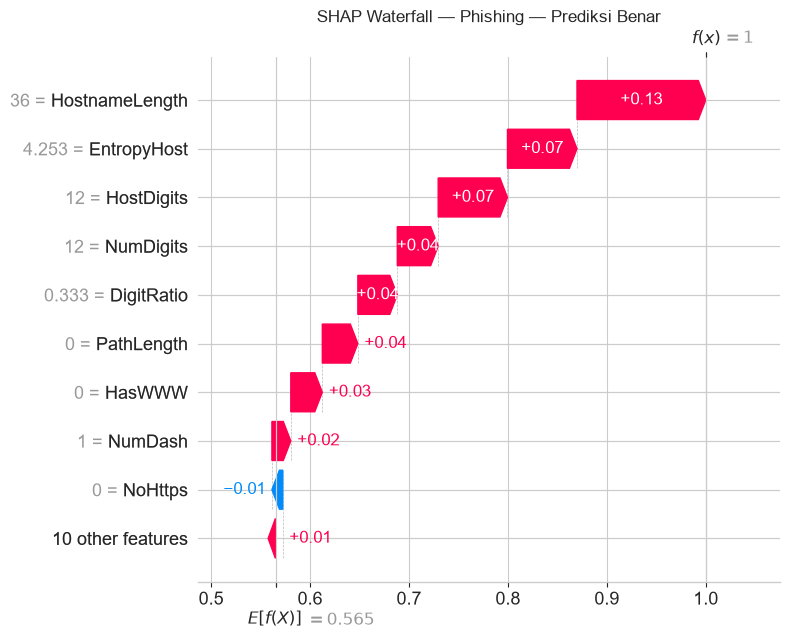

Kasus       : Legitimate — Prediksi Benar
URL         : https://www.acko.com/health-insurance/for-parents/
Label asli  : Legitimate
Prediksi    : Legitimate  (P(Phishing) = 0.0026)


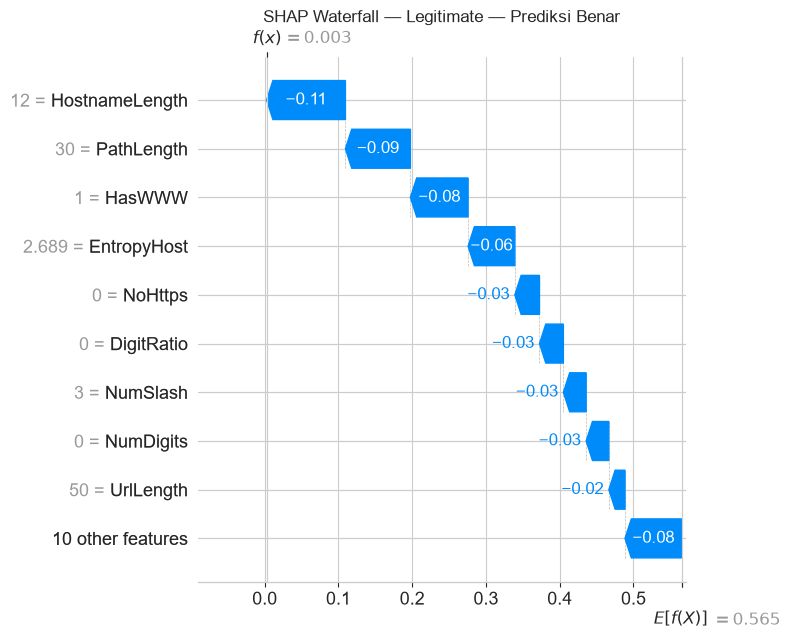

Kasus       : Misklasifikasi
URL         : https://bofamwc.com/exlvt3rtxlssxdo6c/index.html
Label asli  : Phishing
Prediksi    : Legitimate  (P(Phishing) = 0.4528)


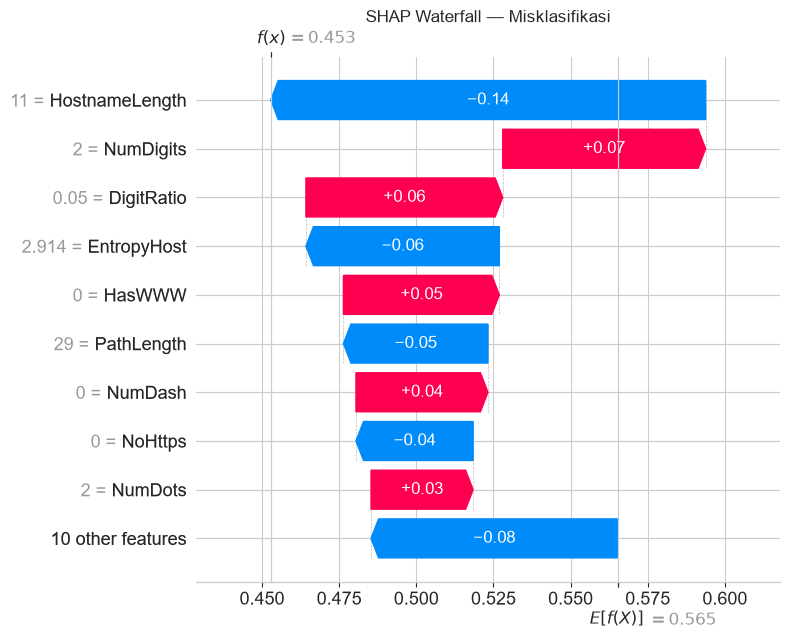

In [33]:
y_pred_sample = model.predict(X_sample)
y_proba_sample = model.predict_proba(X_sample)[:, 1]

sample_meta = pd.DataFrame({
    "actual": y_test.loc[X_sample.index].values,
    "pred": y_pred_sample,
    "proba_phishing": y_proba_sample,
}, index=X_sample.index)

# Pilih sampel representatif:
# 1) Phishing diprediksi benar dengan keyakinan tertinggi
# 2) Legitimate diprediksi benar dengan keyakinan tertinggi
# 3) Sampel misklasifikasi (jika ada)
correct_phishing = sample_meta[(sample_meta["actual"] == 1) & (sample_meta["pred"] == 1)]
correct_legit = sample_meta[(sample_meta["actual"] == 0) & (sample_meta["pred"] == 0)]
misclassified = sample_meta[sample_meta["actual"] != sample_meta["pred"]]

selected_cases = []
if len(correct_phishing) > 0:
    selected_cases.append(("Phishing — Prediksi Benar", correct_phishing["proba_phishing"].idxmax()))
if len(correct_legit) > 0:
    selected_cases.append(("Legitimate — Prediksi Benar", correct_legit["proba_phishing"].idxmin()))
if len(misclassified) > 0:
    selected_cases.append(("Misklasifikasi", misclassified.index[0]))

for case_label, original_idx in selected_cases:
    idx = X_sample.index.get_loc(original_idx)
    sample_url = data_final.loc[original_idx, "url"]
    actual_label = "Phishing" if y_test.loc[original_idx] == 1 else "Legitimate"
    pred_label = "Phishing" if y_pred_sample[idx] == 1 else "Legitimate"

    print("=" * 70)
    print(f"Kasus       : {case_label}")
    print(f"URL         : {sample_url}")
    print(f"Label asli  : {actual_label}")
    print(f"Prediksi    : {pred_label}  (P(Phishing) = {y_proba_sample[idx]:.4f})")

    expl_single = shap.Explanation(
        values=shap_values_phishing[idx],
        base_values=base_value,
        data=X_sample.iloc[idx].values,
        feature_names=feature_cols,
    )

    plt.figure()
    shap.plots.waterfall(expl_single, show=False)
    plt.title(f"SHAP Waterfall — {case_label}")
    plt.tight_layout()
    plt.show()

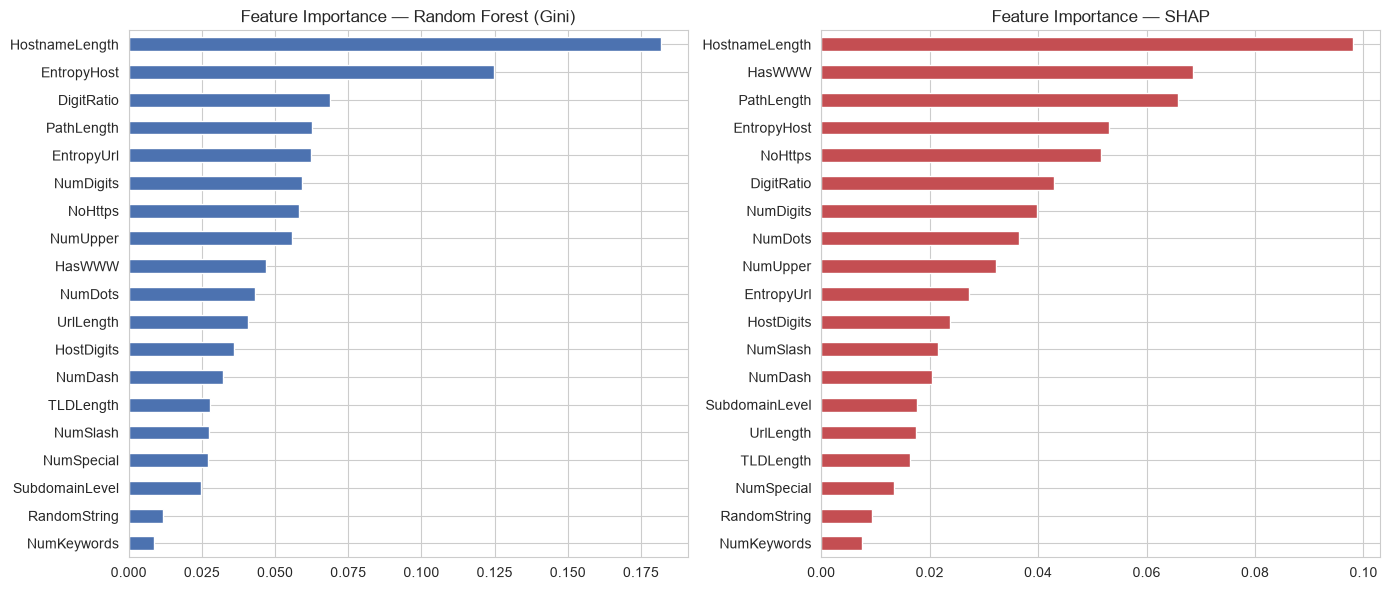

,RF_Gini,SHAP
HostnameLength,0.181800,0.098137
HasWWW,0.047012,0.068637
PathLength,0.062764,0.065759
EntropyHost,0.124719,0.053086
NoHttps,0.058156,0.051596
DigitRatio,0.068802,0.042883
NumDigits,0.059261,0.039861
NumDots,0.043292,0.036387
NumUpper,0.055610,0.032200
EntropyUrl,0.062311,0.027302


In [34]:
rf_importance = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False)
shap_importance = pd.Series(np.abs(shap_values_phishing).mean(axis=0), index=feature_cols).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, max(6, 0.3 * len(feature_cols))))
rf_importance.sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Feature Importance — Random Forest (Gini)")
shap_importance.sort_values().plot.barh(ax=axes[1], color="#C44E52")
axes[1].set_title("Feature Importance — SHAP")
plt.tight_layout()
plt.show()

pd.DataFrame({"RF_Gini": rf_importance, "SHAP": shap_importance}).sort_values("SHAP", ascending=False)

## Implementasi Pipeline Prediksi + Modul Penjelas SHAP *(Tujuan 3)*

Model terbaik disimpan menggunakan `joblib`, kemudian dibangun pipeline end-to-end yang menerima URL mentah, mengekstrak fitur, menjalankan prediksi, menghitung nilai SHAP, dan **menyusun penjelasan berbahasa natural** atas keputusan model — modul inilah yang menjadi dasar sistem penjelas pada aplikasi web (Bagian 8 & aplikasi Streamlit terlampir pada folder `website_streamlit/`).

In [35]:
import shutil
from pathlib import Path

joblib.dump(model, "random_forest_phishing_model.joblib")
joblib.dump(feature_cols, "feature_columns.joblib")
print("Model dan daftar fitur berhasil disimpan di folder notebook.")

# Salin juga ke folder aplikasi agar `streamlit run app.py` selalu memakai model terbaru
# (tanpa langkah ini, app.py tetap membaca model lama di website_streamlit/model/).
app_model_dir = Path("..") / "website_streamlit" / "model"
if app_model_dir.parent.exists():
    app_model_dir.mkdir(exist_ok=True)
    for nama in ("random_forest_phishing_model.joblib", "feature_columns.joblib"):
        shutil.copy2(nama, app_model_dir / nama)
    print(f"Model & daftar fitur ({len(feature_cols)} fitur) disalin ke:", app_model_dir.resolve())
else:
    print("Folder ../website_streamlit tidak ditemukan; salin kedua file .joblib ke website_streamlit/model/ secara manual.")


Model dan daftar fitur berhasil disimpan di folder notebook.
Model & daftar fitur (19 fitur) disalin ke: C:\Users\Rifdatun Nafi'ah\OneDrive - untirta.ac.id\0 fiks PENGEMBANGAN_MODEL_RF_XAI_PHISHING_URL - Salin\PENGEMBANGAN_MODEL_RF_XAI_PHISHING_URL\website_streamlit\model


URL        : https://www.bbc.com/news
Prediksi   : Legitimate  (probabilitas phishing = 0.0730)

Kenapa URL ini diprediksi Legitimate?
  [LEGITIMATE] HostnameLength: panjang hostname wajar (11 karakter)  (kontribusi SHAP = -0.1249)
  [LEGITIMATE] HasWWW: hostname diawali 'www.', pola yang pada dataset penelitian lebih sering ditemukan pada URL legitimate  (kontribusi SHAP = -0.1085)
  [LEGITIMATE] EntropyHost: pola karakter hostname wajar (entropi 2.48)  (kontribusi SHAP = -0.0564)
  [LEGITIMATE] DigitRatio: proporsi angka pada URL wajar (0.00)  (kontribusi SHAP = -0.0475)
  [LEGITIMATE] NumDigits: jumlah angka pada URL wajar (0)  (kontribusi SHAP = -0.0451)


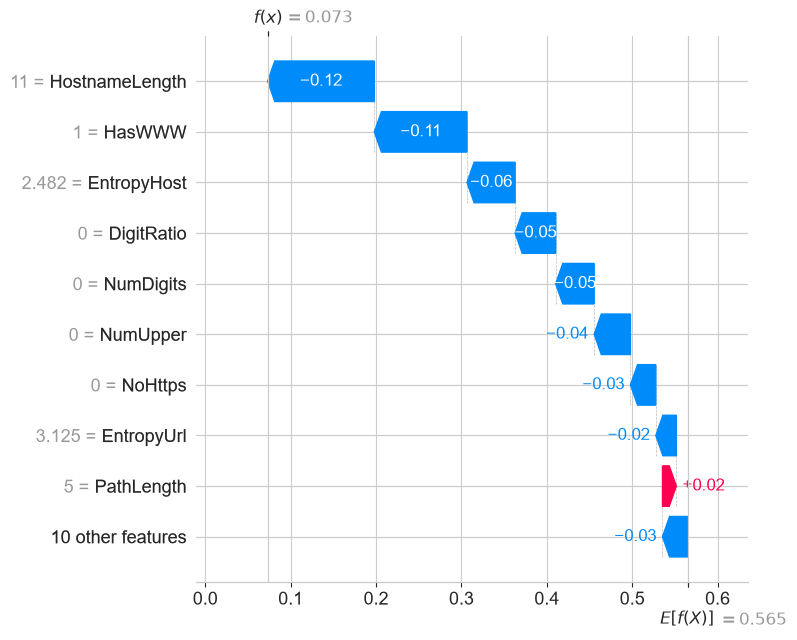

In [36]:
FEATURE_LABELS = {
    "UrlLength": "Panjang URL",
    "NumDots": "Jumlah Titik (.)",
    "SubdomainLevel": "Tingkat Subdomain",
    "NumDash": "Jumlah Tanda Hubung (-)",
    "NumUnderscore": "Jumlah Underscore (_)",
    "NumPercent": "Jumlah Persen (%)",
    "NumQueryComponents": "Jumlah Parameter Query",
    "NumAmpersand": "Jumlah Ampersand (&)",
    "RandomString": "Indikasi String Acak",
    "NoHttps": "Tanpa HTTPS",
    "DomainInPaths": "Domain Muncul di Path",
    "DomainInSubdomains": "Domain Muncul di Subdomain",
    "HTTPSInHostname": "Kata 'https' di Hostname",
    "HostnameLength": "Panjang Hostname",
    # --- fitur tambahan ---
    "PathLength": "Panjang Path",
    "QueryLength": "Panjang Query",
    "NumSlash": "Jumlah Garis Miring (/)",
    "NumDigits": "Jumlah Digit",
    "DigitRatio": "Rasio Digit",
    "NumEquals": "Jumlah Tanda Sama Dengan (=)",
    "NumAt": "Jumlah Simbol @",
    "NumQuestion": "Jumlah Tanda Tanya (?)",
    "HostDigits": "Jumlah Digit di Hostname",
    "IsIP": "Hostname Berupa IP",
    "NumKeywords": "Jumlah Kata Kunci Sensitif",
    "EntropyUrl": "Entropi URL",
    "EntropyHost": "Entropi Hostname",
    "NumSpecial": "Jumlah Karakter Khusus",
    "HasPort": "Port Eksplisit",
    "NumUpper": "Jumlah Huruf Kapital",
    "HasWWW": "Hostname Diawali www",
    "TLDLength": "Panjang TLD",
}
FEATURE_META = {f: {"no": i + 1, "label": FEATURE_LABELS[f]} for i, f in enumerate(FEATURE_ORDER)}

def build_reason_sentence(fname, value, shap_val):
    """Menyusun kalimat penjelasan XAI berbahasa natural untuk satu fitur."""
    pushes_phishing = shap_val > 0
    v = int(value)
    vf = f"{float(value):.2f}"
    templates = {
        "UrlLength": (f"URL cukup panjang ({v} karakter), pola yang sering dipakai untuk menyamarkan domain asli",
                       f"panjang URL wajar ({v} karakter)"),
        "NumDots": (f"URL memiliki cukup banyak tanda titik ({v})", f"jumlah tanda titik pada URL wajar ({v})"),
        "SubdomainLevel": (f"URL memiliki beberapa level subdomain ({v}), teknik umum untuk menyerupai domain resmi",
                            f"struktur subdomain URL sederhana ({v} level)"),
        "NumDash": (f"jumlah tanda hubung pada URL ini ({v}) sesuai pola yang pada dataset penelitian lebih sering ditemukan pada URL phishing",
                     f"jumlah tanda hubung pada URL ini ({v}) sesuai pola yang pada dataset penelitian lebih sering ditemukan pada URL legitimate"),
        "NumUnderscore": (f"jumlah underscore pada URL ini ({v}) sesuai pola yang pada dataset penelitian lebih sering ditemukan pada URL phishing",
                           f"jumlah underscore pada URL ini ({v}) sesuai pola yang pada dataset penelitian lebih sering ditemukan pada URL legitimate"),
        "NumPercent": (f"jumlah karakter encoding '%' pada URL ini ({v}) sesuai pola yang pada dataset penelitian lebih sering ditemukan pada URL phishing",
                        f"jumlah karakter encoding '%' pada URL ini ({v}) sesuai pola yang pada dataset penelitian lebih sering ditemukan pada URL legitimate"),
        "NumQueryComponents": (f"URL membawa cukup banyak parameter query ({v})", f"jumlah parameter query wajar ({v})"),
        "NumAmpersand": (f"URL memiliki beberapa simbol '&' ({v})", f"jumlah simbol '&' wajar ({v})"),
        "RandomString": ("nama domain terindikasi berupa string acak (mirip hasil generate otomatis)",
                          "nama domain tidak menyerupai string acak"),
        "NoHttps": ("URL tidak menggunakan protokol HTTPS yang aman", "URL sudah menggunakan protokol HTTPS"),
        "DomainInPaths": (f"nama domain muncul kembali pada path URL ({v}), pola yang teridentifikasi pada dataset penelitian",
                           f"nama domain tidak diulang secara mencurigakan pada path URL ({v})"),
        "DomainInSubdomains": ("nama domain resmi disisipkan sebagai subdomain, pola khas phishing",
                                "tidak ditemukan penyisipan nama domain pada subdomain"),
        "HTTPSInHostname": ("kata 'https' disisipkan di dalam hostname agar URL terlihat aman secara visual",
                             "tidak ditemukan kata 'https' yang disisipkan mencurigakan pada hostname"),
        "PathLength": (f"path URL cukup panjang ({v} karakter)", f"panjang path URL wajar ({v} karakter)"),
        "QueryLength": (f"query string cukup panjang ({v} karakter)", f"panjang query string wajar ({v} karakter)"),
        "NumSlash": (f"jumlah garis miring (/) pada URL ini ({v}) sesuai pola yang pada dataset penelitian lebih sering ditemukan pada URL phishing",
                     f"jumlah garis miring (/) pada URL ini ({v}) sesuai pola yang pada dataset penelitian lebih sering ditemukan pada URL legitimate"),
        "NumDigits": (f"URL memuat cukup banyak angka ({v})", f"jumlah angka pada URL wajar ({v})"),
        "DigitRatio": (f"proporsi angka pada URL cukup tinggi ({vf})", f"proporsi angka pada URL wajar ({vf})"),
        "NumEquals": (f"URL memiliki beberapa simbol '=' ({v}) yang menandakan banyak parameter", f"jumlah simbol '=' pada URL wajar ({v})"),
        "NumAt": (f"URL memuat simbol '@' ({v}), teknik yang dipakai untuk menyamarkan tujuan sebenarnya", f"tidak ada simbol '@' yang mencurigakan pada URL ({v})"),
        "NumQuestion": (f"jumlah tanda tanya (?) pada URL ini ({v}) sesuai pola yang pada dataset penelitian lebih sering ditemukan pada URL phishing",
                        f"jumlah tanda tanya (?) pada URL ini ({v}) sesuai pola yang pada dataset penelitian lebih sering ditemukan pada URL legitimate"),
        "HostDigits": (f"hostname memuat angka ({v}), pola yang sering muncul pada domain palsu", f"jumlah angka pada hostname wajar ({v})"),
        "IsIP": ("hostname berupa alamat IP, bukan nama domain", "hostname berupa nama domain, bukan alamat IP"),
        "NumKeywords": (f"URL memuat kata kunci sensitif seperti login/secure/verify ({v} kata)", f"tidak ada kata kunci sensitif yang menonjol pada URL ({v})"),
        "EntropyUrl": (f"karakter URL terlihat cukup acak (entropi {vf})", f"pola karakter URL wajar (entropi {vf})"),
        "EntropyHost": (f"karakter hostname terlihat cukup acak (entropi {vf})", f"pola karakter hostname wajar (entropi {vf})"),
        "NumSpecial": (f"URL memuat cukup banyak karakter khusus ({v})", f"jumlah karakter khusus pada URL wajar ({v})"),
        "HasPort": ("URL menuliskan nomor port secara eksplisit", "URL tidak menuliskan port yang tidak lazim"),
        "NumUpper": (f"URL memuat huruf kapital ({v})", f"jumlah huruf kapital pada URL wajar ({v})"),
        "HasWWW": ("hostname tidak diawali 'www.', pola yang pada dataset penelitian lebih sering ditemukan pada URL phishing" if v == 0 else "hostname diawali 'www.' namun kombinasi fitur lain tetap mendorong ke arah phishing",
                   "hostname diawali 'www.', pola yang pada dataset penelitian lebih sering ditemukan pada URL legitimate" if v == 1 else "hostname tidak diawali 'www.' namun kombinasi fitur lain tetap mendorong ke arah legitimate"),
        "TLDLength": (f"panjang TLD ({v} karakter) sesuai pola yang pada dataset penelitian lebih sering ditemukan pada URL phishing", f"panjang TLD ({v} karakter) sesuai pola yang pada dataset penelitian lebih sering ditemukan pada URL legitimate"),
        "HostnameLength": (f"hostname URL cukup panjang ({v} karakter)", f"panjang hostname wajar ({v} karakter)"),
    }
    high_text, low_text = templates.get(fname, (f"nilai fitur {fname} tinggi", f"nilai fitur {fname} wajar"))
    return high_text if pushes_phishing else low_text


def normalize_url(url):
    """Menyeragamkan URL sebelum ekstraksi fitur pada tahap prediksi.

    Garis miring (/) di akhir path tidak mengubah tujuan URL, tetapi menambah 1
    karakter pada fitur UrlLength sehingga https://www.youtube.com/ dan
    https://www.youtube.com bisa mendapat hasil berbeda. Garis miring penutup
    dibuang; skema (http/https) serta query/fragment tidak diubah.
    Normalisasi ini hanya dipakai saat prediksi, jadi model dan seluruh metrik
    evaluasi (Tabel 12) tidak berubah.
    """
    url = str(url).strip()
    m = re.match(r"^([^?#]*)(.*)$", url, flags=re.S)
    base, tail = m.group(1), m.group(2)
    if "://" in base:
        scheme, rest = base.split("://", 1)
        base = scheme + "://" + rest.rstrip("/")
    else:
        base = base.rstrip("/")
    return base + tail


MAX_URL_LENGTH = 2048
_IPV4_RE = re.compile(r"^(?:\d{1,3}\.){3}\d{1,3}$")


def validate_url(raw_url):
    """Validasi format URL SEBELUM diproses model.

    Mengembalikan tuple (valid, alasan). Input dianggap tidak valid jika:
    kosong, terlalu panjang, mengandung spasi, skema bukan http/https,
    tidak punya hostname, atau hostname tidak berbentuk domain/IPv4 yang wajar.
    URL tanpa skema (mis. 'www.bbc.com/news') tetap diterima, sama seperti
    perilaku extract_features yang mengasumsikan 'http://'.
    """
    if raw_url is None or not str(raw_url).strip():
        return False, "input kosong"
    url = str(raw_url).strip()

    if len(url) > MAX_URL_LENGTH:
        return False, f"URL terlalu panjang (> {MAX_URL_LENGTH} karakter)"
    if re.search(r"\s", url):
        return False, "URL mengandung spasi"

    if "://" in url:
        scheme = url.split("://", 1)[0].lower()
        if scheme not in ("http", "https"):
            return False, f"skema '{scheme}://' tidak didukung (hanya http/https)"
        candidate = url
    else:
        candidate = "http://" + url

    try:
        host = urlparse(candidate).hostname
    except ValueError:
        return False, "format URL tidak dapat dibaca"
    if not host:
        return False, "hostname/domain tidak ditemukan"
    host = host.rstrip(".")
    if len(host) > 253:
        return False, "hostname terlalu panjang"

    if _IPV4_RE.match(host):
        if all(0 <= int(p) <= 255 for p in host.split(".")):
            return True, "ok"
        return False, "alamat IP tidak valid"

    labels = host.split(".")
    if len(labels) < 2:
        return False, "hostname tidak berbentuk domain (tidak ada titik/TLD)"
    if not all(re.fullmatch(r"[\w-]{1,63}", lb) for lb in labels):
        return False, "hostname mengandung karakter atau label yang tidak valid"
    if not re.fullmatch(r"xn--[\w-]+|[^\W\d_]{2,}", labels[-1]):
        return False, "TLD tidak valid"
    return True, "ok"



def predict_url(url, trained_model=model, top_n=5, plot=True):
    """
    Modul penjelas SHAP: pipeline end-to-end URL mentah -> label + probabilitas
    + daftar alasan utama (Tujuan 2 & 3).
    """
 
    valid, alasan = validate_url(url)
    if not valid:
        tampil = str(url)[:60] if str(url).strip() else "(string kosong)"
        print(f"URL        : {tampil}")
        print(f"Prediksi   : Input tidak valid, tidak diproses model ({alasan})")
        return {"url": url, "label": "Tidak Valid", "proba_phishing": None,
                "top_reasons": [], "alasan": alasan}

    feats = extract_features(normalize_url(url))
    X_row = pd.DataFrame([feats])[feature_cols]

    pred = int(trained_model.predict(X_row)[0])
    proba = float(trained_model.predict_proba(X_row)[0, 1])
    label = "Phishing" if pred == 1 else "Legitimate"

    sv = explainer.shap_values(X_row)
    sv_phish = sv[1][0] if isinstance(sv, list) else sv[:, :, 1][0]

    contributions = []
    for fname, shap_val in zip(feature_cols, sv_phish):
        contributions.append({
            "feature": fname, "value": feats[fname], "shap": float(shap_val),
            "direction": "phishing" if shap_val > 0 else "legitimate",
            "reason": build_reason_sentence(fname, feats[fname], shap_val),
        })
    contributions_sorted = sorted(contributions, key=lambda c: abs(c["shap"]), reverse=True)
    top_reasons = [c for c in contributions_sorted if c["direction"] == label.lower()][:top_n]

    print(f"URL        : {url}")
    print(f"Prediksi   : {label}  (probabilitas phishing = {proba:.4f})")
    print(f"\nKenapa URL ini diprediksi {label}?")
    for r in top_reasons:
        icon = "[PHISHING]" if r["direction"] == "phishing" else "[LEGITIMATE]"
        fname_r = r["feature"]; reason_r = r["reason"]; shap_r = r["shap"]
        print(f"  {icon} {fname_r}: {reason_r}  (kontribusi SHAP = {shap_r:+.4f})")

    if plot:
        base_value = explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value
        expl_local = shap.Explanation(values=sv_phish, base_values=base_value,
                                       data=X_row.iloc[0].values, feature_names=feature_cols)
        plt.figure()
        shap.plots.waterfall(expl_local, show=False)
        plt.tight_layout()
        plt.show()

    return {"url": url, "label": label, "proba_phishing": proba, "top_reasons": top_reasons}


# Contoh pemakaian: menjawab "kenapa URL ini phishing?" secara eksplisit
_ = predict_url("https://www.bbc.com/news")

URL        : http://secure-login-update.tk/verify/account?id=12345&token=x
Prediksi   : Phishing  (probabilitas phishing = 0.8625)

Kenapa URL ini diprediksi Phishing?
  [PHISHING] NoHttps: URL tidak menggunakan protokol HTTPS yang aman  (kontribusi SHAP = +0.2014)
  [PHISHING] HostnameLength: hostname URL cukup panjang (22 karakter)  (kontribusi SHAP = +0.0618)
  [PHISHING] EntropyUrl: karakter URL terlihat cukup acak (entropi 4.69)  (kontribusi SHAP = +0.0594)
  [PHISHING] EntropyHost: karakter hostname terlihat cukup acak (entropi 3.97)  (kontribusi SHAP = +0.0516)
  [PHISHING] NumKeywords: URL memuat kata kunci sensitif seperti login/secure/verify (5 kata)  (kontribusi SHAP = +0.0401)


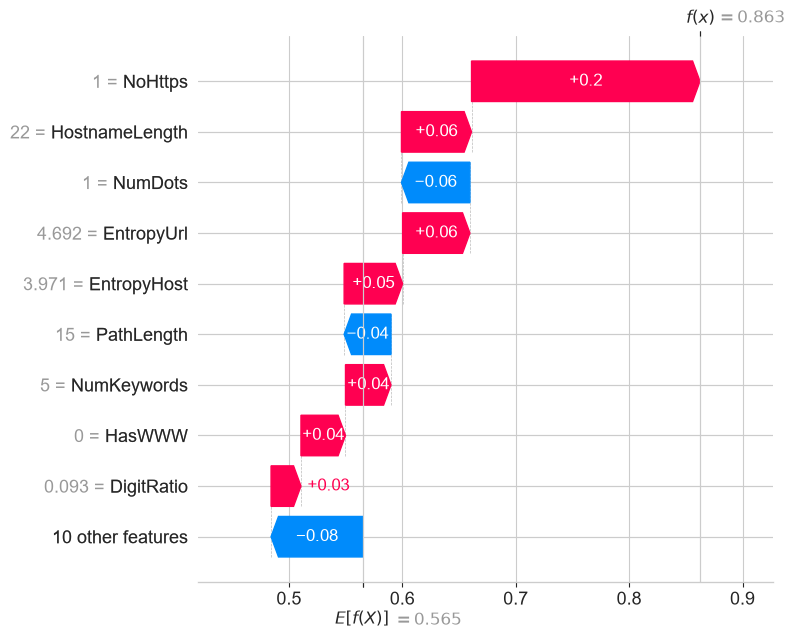

In [37]:
# Contoh kedua: URL dengan kata kunci mencurigakan tetapi struktur sederhana (Sub-bab 4.5.2)
_ = predict_url("http://secure-login-update.tk/verify/account?id=12345&token=x")

### Uji Contoh URL Situs Resmi

Pengecekan cepat pada beberapa URL situs yang diketahui sah, memakai alur yang sama dengan aplikasi (normalisasi URL, ekstraksi fitur, ambang 0,5). Ini hanya contoh, bukan pengganti evaluasi pada data uji.

In [38]:
urls_resmi = [
    "https://untirta.ac.id/",
    "https://siakang.untirta.ac.id/auth/login",
    "https://www.tomoro-coffee.id/",
    "https://www.bulbulls.com/id",
]
for u in urls_resmi:
    fitur = extract_features(normalize_url(u))
    p = float(model.predict_proba(pd.DataFrame([fitur])[feature_cols])[0, 1])
    print(f"{u:45s} P(phishing) = {p:.3f} -> {'PHISHING' if p >= 0.5 else 'LEGITIMATE'}")

https://untirta.ac.id/                        P(phishing) = 0.253 -> LEGITIMATE
https://siakang.untirta.ac.id/auth/login      P(phishing) = 0.460 -> LEGITIMATE
https://www.tomoro-coffee.id/                 P(phishing) = 0.223 -> LEGITIMATE
https://www.bulbulls.com/id                   P(phishing) = 0.101 -> LEGITIMATE


### Pemeriksaan Akhir Model Final

In [39]:
# Pemeriksaan akhir: 4 URL situs resmi harus tetap legitimate pada model final
def _norm(url):
    url = str(url).strip()
    m = re.match(r"^([^?#]*)(.*)$", url, flags=re.S)
    base, tail = m.group(1), m.group(2)
    if "://" in base:
        sch, rest = base.split("://", 1); base = sch + "://" + rest.rstrip("/")
    else:
        base = base.rstrip("/")
    return base + tail

urls_cek = ["https://untirta.ac.id/", "https://siakang.untirta.ac.id/auth/login",
            "https://www.tomoro-coffee.id/", "https://www.bulbulls.com/id"]
semua_legit = True
for u in urls_cek:
    p = float(model.predict_proba(pd.DataFrame([extract_features(_norm(u))])[feature_cols])[0, 1])
    semua_legit &= (p < 0.5)
    print(f"{u:45s} P(phishing) = {p:.3f} -> {'LEGITIMATE' if p < 0.5 else 'PHISHING'}")

metrik_ok = all(v >= 0.90 for v in [acc, prec, rec, f1, auc])
print(f"\nSemua metrik data uji >= 0,90 : {metrik_ok}")
print(f"Keempat URL tetap legitimate  : {semua_legit}")
if not (metrik_ok and semua_legit):
    print(">>> Belum terpenuhi. Turunkan PI_THRESHOLD (mis. 0.0005) pada sel seleksi fitur lalu jalankan ulang dari sana.")

https://untirta.ac.id/                        P(phishing) = 0.253 -> LEGITIMATE
https://siakang.untirta.ac.id/auth/login      P(phishing) = 0.460 -> LEGITIMATE
https://www.tomoro-coffee.id/                 P(phishing) = 0.223 -> LEGITIMATE
https://www.bulbulls.com/id                   P(phishing) = 0.101 -> LEGITIMATE

Semua metrik data uji >= 0,90 : True
Keempat URL tetap legitimate  : True


## Pengujian Sistem (Black-Box Testing) *(Tujuan 3)*

Pipeline model + modul penjelas SHAP diuji melalui empat skenario *black-box testing* untuk memastikan sistem dapat digunakan secara praktis dan andal.

In [40]:
print("=== (1) & (2) Uji Prediksi Tunggal & Batch ===")
test_urls = [
    "https://www.bbc.com/news",
    "https://www.tokopedia.com",
    "http://update-account-security-paypal.net/login",
    "http://verify-appleid.billing-confirmation.com",
    "http://klikbca-login-verifikasidata.com",
]
for u in test_urls:
    r = predict_url(u, plot=False)
    print("-" * 60)

=== (1) & (2) Uji Prediksi Tunggal & Batch ===
URL        : https://www.bbc.com/news
Prediksi   : Legitimate  (probabilitas phishing = 0.0730)

Kenapa URL ini diprediksi Legitimate?
  [LEGITIMATE] HostnameLength: panjang hostname wajar (11 karakter)  (kontribusi SHAP = -0.1249)
  [LEGITIMATE] HasWWW: hostname diawali 'www.', pola yang pada dataset penelitian lebih sering ditemukan pada URL legitimate  (kontribusi SHAP = -0.1085)
  [LEGITIMATE] EntropyHost: pola karakter hostname wajar (entropi 2.48)  (kontribusi SHAP = -0.0564)
  [LEGITIMATE] DigitRatio: proporsi angka pada URL wajar (0.00)  (kontribusi SHAP = -0.0475)
  [LEGITIMATE] NumDigits: jumlah angka pada URL wajar (0)  (kontribusi SHAP = -0.0451)
------------------------------------------------------------
URL        : https://www.tokopedia.com
Prediksi   : Legitimate  (probabilitas phishing = 0.0952)

Kenapa URL ini diprediksi Legitimate?
  [LEGITIMATE] HasWWW: hostname diawali 'www.', pola yang pada dataset penelitian lebih s

In [41]:
print("=== (3) Uji Ketahanan terhadap Input Tidak Valid ===")
edge_case_urls = ["", "bukan_url_yang_valid", "ftp://192.168.1.1/file", "http://", "a" * 500,
                  "https://www.bbc.com/news"]

for u in edge_case_urls:
    alasan = ""
    try:
        valid, alasan = validate_url(u)
        if not valid:
            status = "DITOLAK (tidak valid)"
            label = "-"
        else:
            feats = extract_features(u)
            pred = model.predict(pd.DataFrame([feats])[feature_cols])[0]
            status = "BERHASIL diproses"
            label = "Phishing" if pred == 1 else "Legitimate"
    except Exception as e:
        status = f"GAGAL: {e}"
        label = "-"
    display_url = (u[:40] + "...") if len(u) > 40 else (u if u else "(string kosong)")
    print(f"Input: {display_url:45s} | Status: {status:24s} | Prediksi: {label}" + (f" | Alasan: {alasan}" if status.startswith("DITOLAK") else ""))


=== (3) Uji Ketahanan terhadap Input Tidak Valid ===
Input: (string kosong)                               | Status: DITOLAK (tidak valid)    | Prediksi: - | Alasan: input kosong
Input: bukan_url_yang_valid                          | Status: DITOLAK (tidak valid)    | Prediksi: - | Alasan: hostname tidak berbentuk domain (tidak ada titik/TLD)
Input: ftp://192.168.1.1/file                        | Status: DITOLAK (tidak valid)    | Prediksi: - | Alasan: skema 'ftp://' tidak didukung (hanya http/https)
Input: http://                                       | Status: DITOLAK (tidak valid)    | Prediksi: - | Alasan: hostname/domain tidak ditemukan
Input: aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaa...   | Status: DITOLAK (tidak valid)    | Prediksi: - | Alasan: hostname terlalu panjang
Input: https://www.bbc.com/news                      | Status: BERHASIL diproses        | Prediksi: Legitimate


In [42]:
print("=== (4) Uji Konsistensi Model Tersimpan vs Model Asli ===")
loaded_model = joblib.load("random_forest_phishing_model.joblib")

sample_check = X_test.sample(n=300, random_state=1)
pred_original = model.predict(sample_check)
pred_loaded = loaded_model.predict(sample_check)

is_consistent = np.array_equal(pred_original, pred_loaded)
print("Prediksi model asli dan model yang dimuat ulang konsisten (n=300):", is_consistent)

=== (4) Uji Konsistensi Model Tersimpan vs Model Asli ===
Prediksi model asli dan model yang dimuat ulang konsisten (n=300): True
